# BRICS Fragment Enrichment: Mitochondrial Activity & Cell Viability (MMP)

All enrichment uses **Fisher's exact test** (one-tailed, fragment-in vs fragment-out),  
Benjamini–Hochberg FDR correction, and the BRICS decomposition from RDKit.

SMILES source: `PUBCHEM_EXT_DATASOURCE_SMILES` from the result CSV files directly.

---

## Analyses covered

| Analysis | Groups | Source table |
|----------|--------|--------------|
| **A** | Mito+Viability **Both Active** vs **Both Inactive** | Table 7 |
| **B** | Mitochondria **Active** vs **Inactive** (irrespective of viability) | Mito assay |


In [214]:
import pandas as pd
import numpy as np
import re
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import fisher_exact
from scipy.stats.contingency import odds_ratio as cond_or
from statsmodels.stats.multitest import multipletests

from rdkit import Chem
from rdkit.Chem import BRICS, Draw
from IPython.display import display, SVG

warnings.filterwarnings('ignore')

BASE     = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
RES      = BASE + 'results/'
MITO_VIB = RES + 'mito_viability_comparisons/'

# ── SMILES loader ─────────────────────────────────────────────────────────────
def load_cid_smiles(path):
    df = pd.read_csv(path,
                     usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                     low_memory=False)
    df = df.dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    df = df.drop_duplicates('PUBCHEM_CID').reset_index(drop=True)
    return df[['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES']].rename(
        columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'smiles'})

def load_and_concat(paths):
    frames = [load_cid_smiles(p) for p in paths]
    combined = pd.concat(frames, ignore_index=True)
    return combined.drop_duplicates('PUBCHEM_CID').reset_index(drop=True)

# ── BRICS helpers ─────────────────────────────────────────────────────────────
def brics_frags(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return frozenset(BRICS.BRICSDecompose(mol)) if mol else frozenset()

def clean_frag(frag_smi):
    return re.sub(r'\[\d+\*\]', '[H]', frag_smi)

# ── Core enrichment with conditional MLE OR + 95% CI ─────────────────────────
def fisher_enrichment(group_a_sets, group_b_sets, label_a='A', label_b='B',
                      min_count=3, fdr_alpha=0.05, min_or=0):
    """
    Fisher exact enrichment test with conditional MLE odds ratio and 95% CI.
    Returns DataFrame with columns: fragment, n_A, pct_A, n_B, pct_B,
                                    odds_ratio, ci_lo, ci_hi, pvalue, padj
    """
    na, nb = len(group_a_sets), len(group_b_sets)
    all_frags = set().union(*group_a_sets, *group_b_sets)
    rows = []
    for frag in all_frags:
        a = sum(1 for fs in group_a_sets if frag in fs)
        c = sum(1 for fs in group_b_sets if frag in fs)
        if a < min_count:
            continue
        b, d = na - a, nb - c
        # One-tailed p-value
        _, pval = fisher_exact([[a, b], [c, d]], alternative='greater')
        # Conditional MLE OR and 95% CI
        res = cond_or(np.array([[a, b], [c, d]]), kind='conditional')
        ci  = res.confidence_interval(confidence_level=0.95)
        rows.append({
            'fragment':       frag,
            f'n_{label_a}':   a,
            f'pct_{label_a}': 100 * a / na,
            f'n_{label_b}':   c,
            f'pct_{label_b}': 100 * c / nb,
            'odds_ratio':     res.statistic,
            'ci_lo':          ci.low,
            'ci_hi':          ci.high,
            'pvalue':         pval,
        })
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows)
    _, padj, _, _ = multipletests(df['pvalue'], method='fdr_bh')
    df['padj'] = padj
    df = df[(df['padj'] < fdr_alpha) & (df['odds_ratio'] >= min_or)].sort_values('padj')
    return df.reset_index(drop=True)

# ── Visualisation helpers ─────────────────────────────────────────────────────
def draw_frags(enrich_df, title, top_n=12, mols_per_row=4):
    """Draw top enriched BRICS fragments; legend shows OR and 95% CI."""
    mols, legs = [], []
    for _, row in enrich_df.head(top_n).iterrows():
        mol = Chem.MolFromSmiles(clean_frag(row['fragment']))
        if mol:
            mols.append(mol)
            or_  = row['odds_ratio']
            lo   = row.get('ci_lo', np.nan)
            hi   = row.get('ci_hi', np.nan)
            padj = row['padj']
            or_s = f'{or_:.1f}' if not np.isinf(or_) else 'inf'
            lo_s = f'{lo:.1f}' if not np.isinf(lo) else 'inf'
            hi_s = f'{hi:.1f}' if not np.isinf(hi) else 'inf'
            leg  = 'OR=' + or_s + ' (' + lo_s + ',' + hi_s + ')' + ' padj=' + f'{padj:.1e}'
            legs.append(leg)
    if not mols:
        print('No drawable fragments for: ' + title)
        return
    svg = Draw.MolsToGridImage(mols, molsPerRow=mols_per_row,
                               subImgSize=(450, 360),
                               legends=legs, useSVG=True)
    print('\n' + title + ' — top ' + str(len(mols)) + ' enriched BRICS fragments:')
    display(svg)

def bar_enrichment(enrich_df, title, top_n=20):
    """Horizontal bar chart of OR with 95% CI error bars."""
    top = enrich_df.head(top_n).copy()
    if top.empty:
        print('No significant fragments for: ' + title)
        return
    # Cap infinite values for display only
    max_finite = top['odds_ratio'].replace(np.inf, np.nan).max()
    cap = max_finite * 1.5 if (max_finite is not None and not np.isnan(max_finite)) else 50
    or_plot = top['odds_ratio'].clip(upper=cap).values[::-1]
    ci_lo   = top['ci_lo'].clip(upper=cap).values[::-1]
    ci_hi   = top['ci_hi'].clip(upper=cap).values[::-1]
    xerr_lo = or_plot - ci_lo
    xerr_hi = ci_hi - or_plot
    labels  = [f[:45] for f in top['fragment']][::-1]
    colors  = ['#d62728' if v >= 3 else '#ff7f0e' for v in top['odds_ratio']][::-1]
    fig, ax = plt.subplots(figsize=(11, max(5, 0.35 * len(top))))
    ax.barh(labels, or_plot, color=colors, alpha=0.7)
    ax.errorbar(or_plot, labels,
                xerr=[xerr_lo, xerr_hi],
                fmt='none', color='black', capsize=3, linewidth=1)
    ax.axvline(1, color='black', linestyle='--', linewidth=0.8)
    ax.set_xlabel('Odds Ratio (conditional MLE, 95% CI)')
    ax.set_title(title, fontsize=11)
    red    = mpatches.Patch(color='#d62728', label='OR >= 3 (strongly enriched)')
    orange = mpatches.Patch(color='#ff7f0e', label='OR 1-3 (moderately enriched)')
    ax.legend(handles=[red, orange], fontsize=8)
    plt.tight_layout()
    plt.show()

print('Setup complete — fisher_enrichment now returns OR + 95% CI (conditional MLE).')


Setup complete — fisher_enrichment now returns OR + 95% CI (conditional MLE).


---
## Analysis A — Table 7: Mitochondrial Membrane Potential (MMP) vs Cell Viability

Pairwise outcome groups (unique CIDs, HepG2):

| Group | Description | N |
|-------|-------------|---|
| **Both Active** | Active in both MMP and cell viability assays | 292 |
| **Both Inactive** | Inactive in both assays | 3,196 |

**Thresholds:** min\_count=3, FDR $\alpha/bin/zsh.01, OR$\geq

**Question:** Which BRICS fragments are uniquely enriched in the both-active group?  
These fragments signal structural motifs that simultaneously disrupt mitochondrial membrane potential and reduce cell viability.


In [215]:
# ── Load Table 7 groups ──────────────────────────────────────────────────────
t7_active   = load_cid_smiles(MITO_VIB + 'mito_and_mito_viability_active.csv')
t7_inactive = load_cid_smiles(MITO_VIB + 'mito_inactive_and_mito_viability_inactive.csv')

print(f'Both Active  (Mito+Viability): {len(t7_active):5d} unique CIDs')
print(f'Both Inactive (Mito+Viability): {len(t7_inactive):5d} unique CIDs')

# ── BRICS fragment sets ──────────────────────────────────────────────────────
t7_active_sets   = [brics_frags(s) for s in t7_active['smiles']]
t7_inactive_sets = [brics_frags(s) for s in t7_inactive['smiles']]

print(f'\nFragments computed for {sum(len(s)>0 for s in t7_active_sets)}/{len(t7_active_sets)} active compounds')
print(f'Fragments computed for {sum(len(s)>0 for s in t7_inactive_sets)}/{len(t7_inactive_sets)} inactive compounds')

Both Active  (Mito+Viability):   292 unique CIDs
Both Inactive (Mito+Viability):  3196 unique CIDs


[17:41:12] WARNING: not removing hydrogen atom without neighbors
[17:41:12] WARNING: not removing hydrogen atom without neighbors
[17:41:13] WARNING: not removing hydrogen atom without neighbors



Fragments computed for 292/292 active compounds
Fragments computed for 3196/3196 inactive compounds


In [216]:
# ── Fisher's test: both-active vs both-inactive ──────────────────────────────
# Thresholds: min_count=3, fdr_alpha=0.01, min_or=2  →  17 fragments
enrich_t7 = fisher_enrichment(
    t7_active_sets, t7_inactive_sets,
    label_a='both_active', label_b='both_inactive',
    min_count=3, fdr_alpha=0.01, min_or=2
)

print(f'Significantly enriched fragments in Both-Active vs Both-Inactive: {len(enrich_t7)}')
if not enrich_t7.empty:
    cols = ['fragment', 'n_both_active', 'pct_both_active',
            'n_both_inactive', 'pct_both_inactive', 'odds_ratio', 'padj']
    print(enrich_t7[cols].to_string(index=False))


Significantly enriched fragments in Both-Active vs Both-Inactive: 17
                                      fragment  n_both_active  pct_both_active  n_both_inactive  pct_both_inactive  odds_ratio     padj
                              [16*]c1ccc(O)cc1             18         6.164384               35           1.095119    5.927218 0.000006
                            [5*][N+]([5*])(C)C              9         3.082192                6           0.187735   16.874899 0.000017
                                  [8*]C(F)(F)F             14         4.794521               25           0.782228    6.380908 0.000027
                                  [8*]C(C)(C)C             12         4.109589               19           0.594493    7.157881 0.000046
                              [3*]OP(=S)(OC)OC              5         1.712329                1           0.031289   55.504177 0.000263
                            [16*]c1cc(Cl)ccc1O              4         1.369863                0           0.000000 

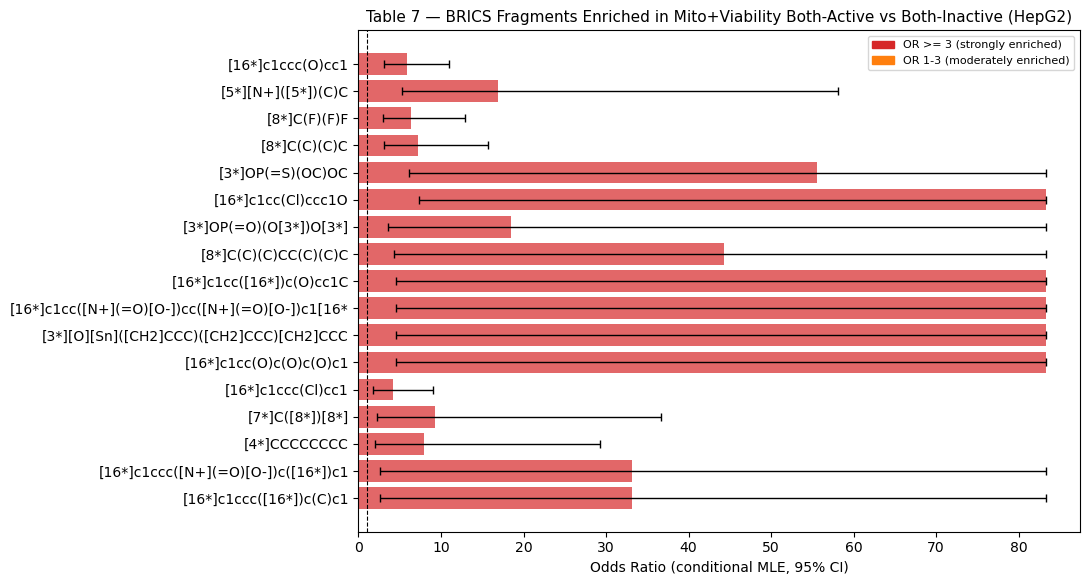


Table 7 — Top Enriched BRICS Fragments (Mito+Viability Both-Active, HepG2) — top 12 enriched BRICS fragments:


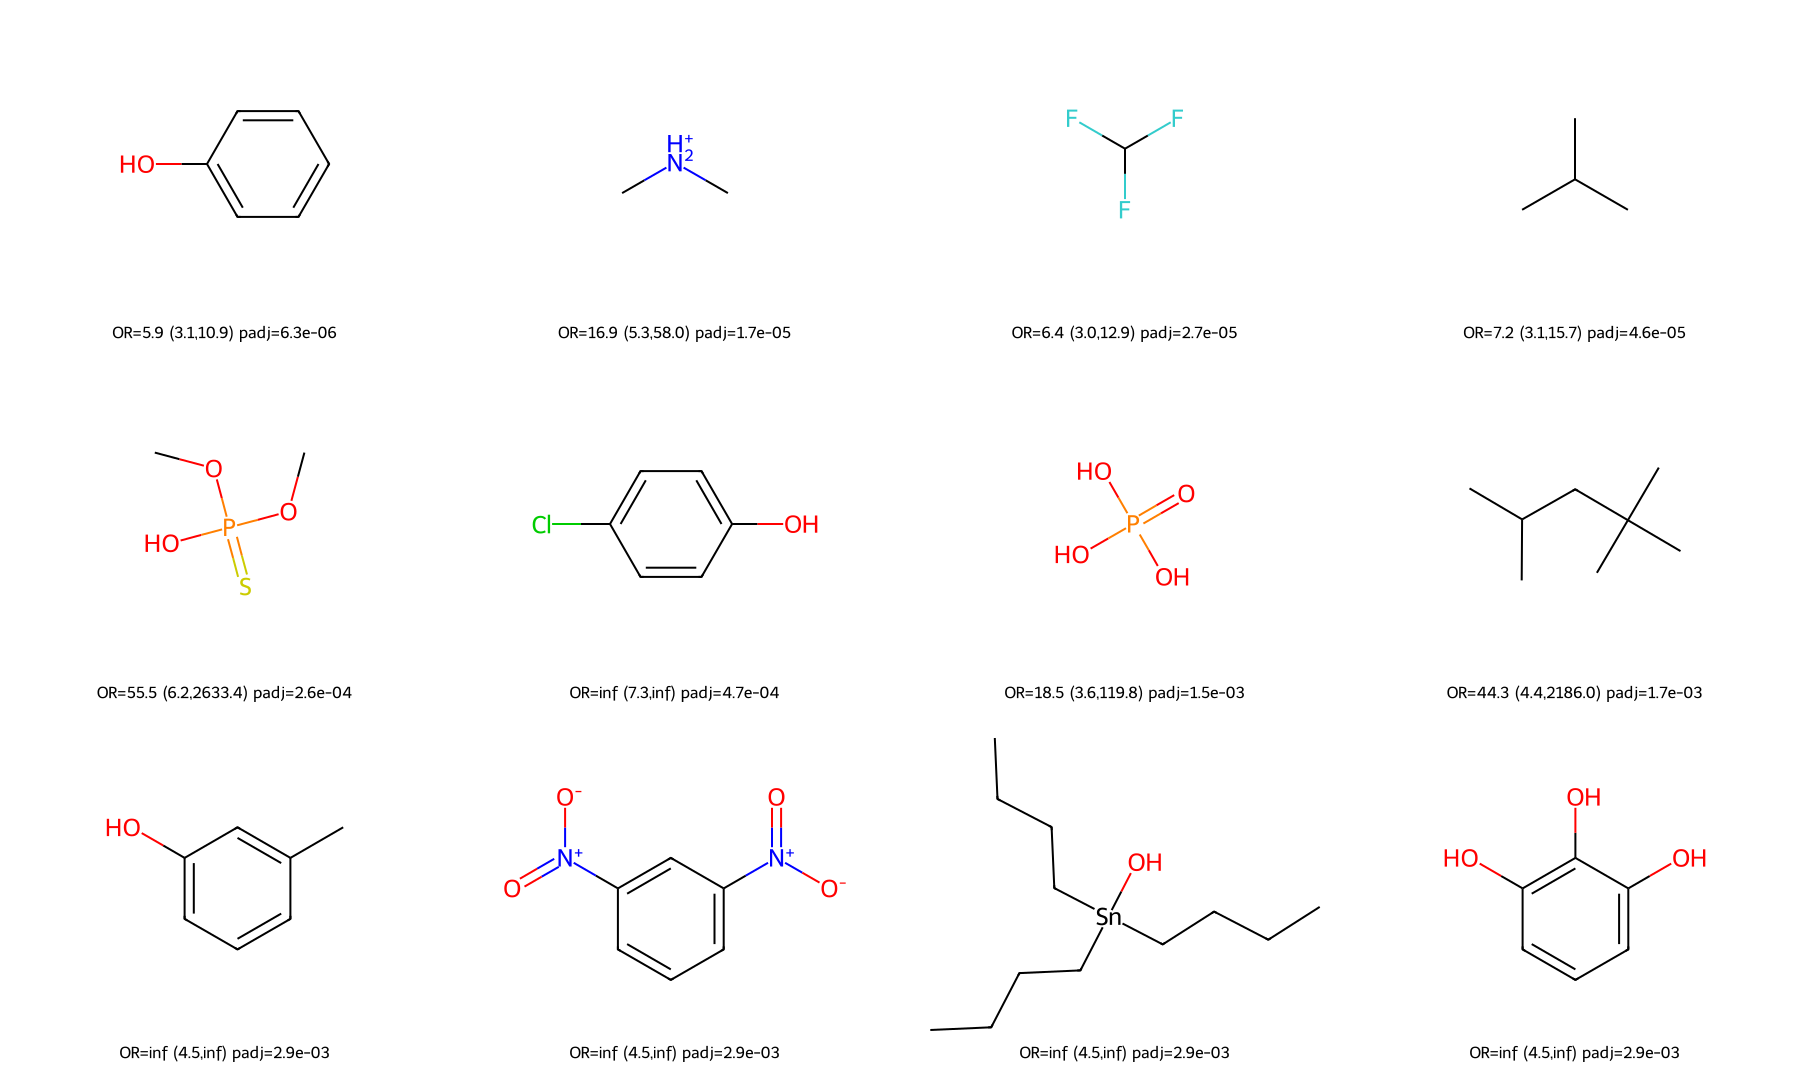

In [217]:
# ── Bar chart ────────────────────────────────────────────────────────────────
bar_enrichment(
    enrich_t7,
    title='Table 7 — BRICS Fragments Enriched in Mito+Viability Both-Active vs Both-Inactive (HepG2)'
)

# ── Structure grid ───────────────────────────────────────────────────────────
draw_frags(
    enrich_t7,
    title='Table 7 — Top Enriched BRICS Fragments (Mito+Viability Both-Active, HepG2)'
)

Fragments enriched in Both-INACTIVE (depleted in both-active): 1
  fragment  n_both_inactive  pct_both_inactive  n_both_active  pct_both_active  odds_ratio     padj
[6*]C(=O)O              136           4.255319              0              0.0         inf 0.000412


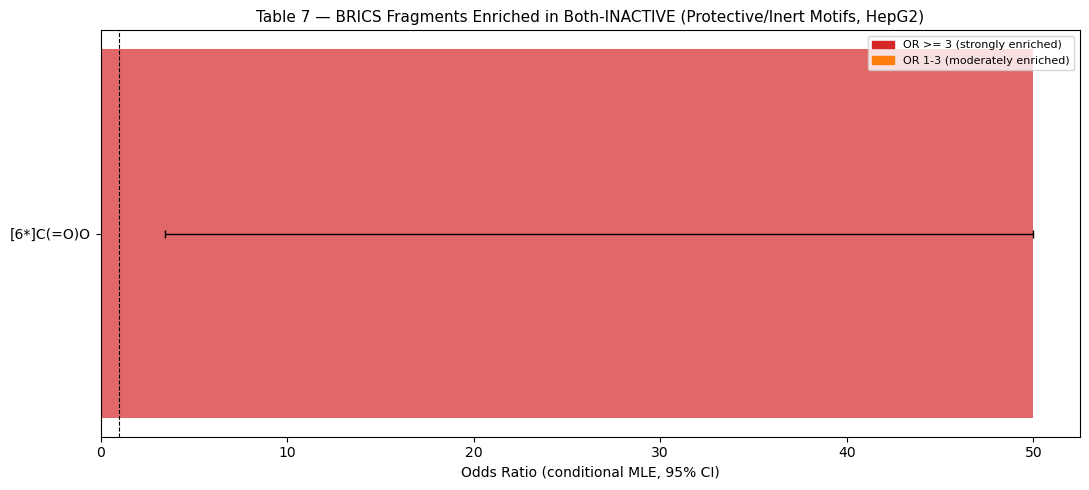


Table 7 — Top BRICS Fragments Enriched in Both-Inactive (HepG2) — top 1 enriched BRICS fragments:


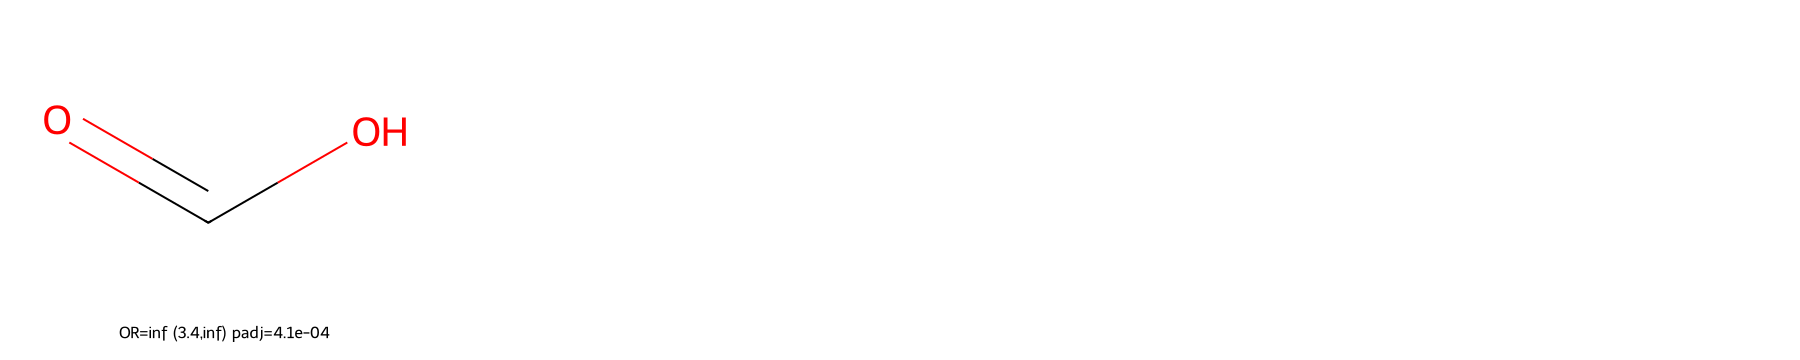

In [218]:
# ── Reverse direction: fragments enriched in BOTH-INACTIVE ──────────────────
# Fragments depleted in both-active (i.e. characteristic of non-toxic compounds)
enrich_t7_inv = fisher_enrichment(
    t7_inactive_sets, t7_active_sets,
    label_a='both_inactive', label_b='both_active',
    min_count=15, fdr_alpha=0.05
)

print(f'Fragments enriched in Both-INACTIVE (depleted in both-active): {len(enrich_t7_inv)}')
if not enrich_t7_inv.empty:
    print(enrich_t7_inv[['fragment', 'n_both_inactive', 'pct_both_inactive',
                          'n_both_active', 'pct_both_active', 'odds_ratio', 'padj']].head(15).to_string(index=False))

bar_enrichment(
    enrich_t7_inv,
    title='Table 7 — BRICS Fragments Enriched in Both-INACTIVE (Protective/Inert Motifs, HepG2)'
)
draw_frags(
    enrich_t7_inv,
    title='Table 7 — Top BRICS Fragments Enriched in Both-Inactive (HepG2)'
)

In [219]:
# ── Generate fragment PNG images for Analysis A (Table 7) LaTeX table ────────
import os
from rdkit.Chem.Draw import rdMolDraw2D

FIGS = BASE + 'figures/'
os.makedirs(FIGS, exist_ok=True)

def save_frag_png(filename, brics_smi, size=(300, 250)):
    mol = Chem.MolFromSmiles(clean_frag(brics_smi))
    if not mol:
        print(f'  FAILED: {filename}'); return
    drawer = rdMolDraw2D.MolDraw2DCairo(*size)
    drawer.drawOptions().addStereoAnnotation = False
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    with open(FIGS + filename, 'wb') as fh:
        fh.write(drawer.GetDrawingText())
    print(f'  OK: {filename}')

# (filename, BRICS SMILES)
# Phenolic family
save_frag_png('t7_frag_phenol.png',             '[16*]c1ccc(O)cc1')
save_frag_png('t7_frag_pyrogallol.png',          '[16*]c1cc(O)c(O)c(O)c1')
save_frag_png('t7_frag_mcresol.png',             '[16*]c1cc([16*])c(O)cc1C')
save_frag_png('t7_frag_hydroxyphenyl_disub.png', '[16*]c1ccc(O)c([16*])c1')
# Chlorinated aromatic
save_frag_png('t7_frag_chlorophenol.png',        '[16*]c1cc(Cl)ccc1O')
save_frag_png('t7_frag_chlorobenzene.png',       '[16*]c1ccc(Cl)cc1')
save_frag_png('t7_frag_dichlorophenyl.png',      '[16*]c1ccc(Cl)c(Cl)c1')
# Nitroaromatic
save_frag_png('t7_frag_dinitrobenzene.png',      '[16*]c1cc([N+](=O)[O-])cc([N+](=O)[O-])c1[16*]')
save_frag_png('t7_frag_nitrobenzene_ortho.png',  '[16*]c1ccc([N+](=O)[O-])c([16*])c1')
save_frag_png('t7_frag_nitrophenyl_meta.png',    '[16*]c1cccc([N+](=O)[O-])c1')
save_frag_png('t7_frag_nitrophenyl_para.png',    '[16*]c1ccc([N+](=O)[O-])cc1')
# General aromatic
save_frag_png('t7_frag_phenyl_disub.png',        '[16*]c1ccc([16*])cc1')
save_frag_png('t7_frag_tolyl_disub.png',         '[16*]c1ccc([16*])c(C)c1')
save_frag_png('t7_frag_phenyl.png',              '[16*]c1ccccc1')
# Lipophilic / alkyl chain
save_frag_png('t7_frag_tbutyl.png',              '[8*]C(C)(C)C')
save_frag_png('t7_frag_isooctyl.png',            '[8*]C(C)(C)CC(C)(C)C')
save_frag_png('t7_frag_methine.png',             '[7*]C([8*])[8*]')
save_frag_png('t7_frag_octyl.png',               '[4*]CCCCCCCC')
save_frag_png('t7_frag_methylene.png',           '[8*]C[8*]')
save_frag_png('t7_frag_secbutyl.png',            '[8*]C(C)CC')
save_frag_png('t7_frag_isopropyl.png',           '[8*]C(C)C')
save_frag_png('t7_frag_dodecyl.png',             '[8*]CCCCCCCCCCCC')
save_frag_png('t7_frag_isobutyl_disub.png',      '[8*]C([8*])(C)C')
# Nitrogen-containing
save_frag_png('t7_frag_dimethylamine.png',       '[5*][N+]([5*])(C)C')
save_frag_png('t7_frag_triazole.png',            '[9*]n1cncn1')
# Organophosphate
save_frag_png('t7_frag_dimethylthiophosphate.png','[3*]OP(=S)(OC)OC')
save_frag_png('t7_frag_phosphate.png',           '[3*]OP(=O)(O[3*])O[3*]')
save_frag_png('t7_frag_thiophosphate.png',       '[3*]OP(=S)(O[3*])O[3*]')
# Halogenated
save_frag_png('t7_frag_cf3.png',                 '[8*]C(F)(F)F')
# Organometallic
save_frag_png('t7_frag_tributyltin.png',         '[3*]O[Sn](CCCC)(CCCC)CCCC')
print("All Analysis A fragment PNGs saved.")


  OK: t7_frag_phenol.png
  OK: t7_frag_pyrogallol.png
  OK: t7_frag_mcresol.png
  OK: t7_frag_hydroxyphenyl_disub.png
  OK: t7_frag_chlorophenol.png
  OK: t7_frag_chlorobenzene.png
  OK: t7_frag_dichlorophenyl.png
  OK: t7_frag_dinitrobenzene.png
  OK: t7_frag_nitrobenzene_ortho.png
  OK: t7_frag_nitrophenyl_meta.png
  OK: t7_frag_nitrophenyl_para.png
  OK: t7_frag_phenyl_disub.png
  OK: t7_frag_tolyl_disub.png
  OK: t7_frag_phenyl.png
  OK: t7_frag_tbutyl.png
  OK: t7_frag_isooctyl.png
  OK: t7_frag_methine.png
  OK: t7_frag_octyl.png
  OK: t7_frag_methylene.png
  OK: t7_frag_secbutyl.png
  OK: t7_frag_isopropyl.png
  OK: t7_frag_dodecyl.png
  OK: t7_frag_isobutyl_disub.png
  OK: t7_frag_dimethylamine.png
  OK: t7_frag_triazole.png
  OK: t7_frag_dimethylthiophosphate.png
  OK: t7_frag_phosphate.png
  OK: t7_frag_thiophosphate.png
  OK: t7_frag_cf3.png
  OK: t7_frag_tributyltin.png
All Analysis A fragment PNGs saved.


---
## Analysis B — Mitochondrial Membrane Potential (MMP): Active vs Inactive

Here we ask purely about the **mitochondrial assay** outcome, irrespective of cell viability.

| Group | Description | Source files |
|-------|-------------|------------------|
| **Mito Active** | Active in MMP assay (viability outcome: any) | `mito_and_mito_viability_active` + `mito_active_and_mito_viability_inctive` |
| **Mito Inactive** | Inactive in MMP assay | `mito_inactive_and_mito_viability_inactive` |

**Question:** Which BRICS fragments are uniquely enriched among compounds that disrupt mitochondrial membrane potential?  
These structural motifs may serve as warnings for mitochondrial toxicity.


In [220]:
# ── Load Mito Active (union of both sub-groups) ──────────────────────────────
mito_active   = load_and_concat([
    MITO_VIB + 'mito_and_mito_viability_active.csv',
    MITO_VIB + 'mito_active_and_mito_viability_inctive.csv',
])

# ── Load Mito Inactive ───────────────────────────────────────────────────────
mito_inactive = load_cid_smiles(MITO_VIB + 'mito_inactive_and_mito_viability_inactive.csv')

print(f'Mito Active  : {len(mito_active):5d} unique CIDs')
print(f'Mito Inactive: {len(mito_inactive):5d} unique CIDs')

# ── BRICS fragment sets ──────────────────────────────────────────────────────
mito_active_sets   = [brics_frags(s) for s in mito_active['smiles']]
mito_inactive_sets = [brics_frags(s) for s in mito_inactive['smiles']]

print(f'\nFragments computed for {sum(len(s)>0 for s in mito_active_sets)}/{len(mito_active_sets)} active')
print(f'Fragments computed for {sum(len(s)>0 for s in mito_inactive_sets)}/{len(mito_inactive_sets)} inactive')

Mito Active  :   972 unique CIDs
Mito Inactive:  3196 unique CIDs


[17:41:42] WARNING: not removing hydrogen atom without neighbors
[17:41:42] WARNING: not removing hydrogen atom without neighbors
[17:41:44] WARNING: not removing hydrogen atom without neighbors



Fragments computed for 972/972 active
Fragments computed for 3196/3196 inactive


In [221]:
# ── Fisher's test: mito-active vs mito-inactive ──────────────────────────────
enrich_mito = fisher_enrichment(
    mito_active_sets, mito_inactive_sets,
    label_a='mito_active', label_b='mito_inactive',
    min_count=6, fdr_alpha=0.01, min_or=2
)

print(f'Significantly enriched fragments in Mito-Active vs Mito-Inactive: {len(enrich_mito)}')
if not enrich_mito.empty:
    cols = ['fragment', 'n_mito_active', 'pct_mito_active',
            'n_mito_inactive', 'pct_mito_inactive', 'odds_ratio', 'padj']
    print(enrich_mito[cols].head(15).to_string(index=False))

Significantly enriched fragments in Mito-Active vs Mito-Inactive: 24
                                   fragment  n_mito_active  pct_mito_active  n_mito_inactive  pct_mito_inactive  odds_ratio         padj
                           [16*]c1ccc(O)cc1             47         4.835391               35           1.095119    4.586779 1.665957e-09
                               [8*]C(C)(C)C             31         3.189300               19           0.594493    5.505607 1.633592e-07
                               [8*]C(F)(F)F             27         2.777778               25           0.782228    3.622584 1.455246e-04
                     [16*]c1cc(O)c(O)c(O)c1              7         0.720165                0           0.000000         inf 3.689396e-04
                         [5*][N+]([5*])(C)C             13         1.337449                6           0.187735    7.202758 3.689396e-04
[13*][C@H]1C[C@H](O)[C@H]([15*])[C@@H](C)O1              7         0.720165                0           0.0000

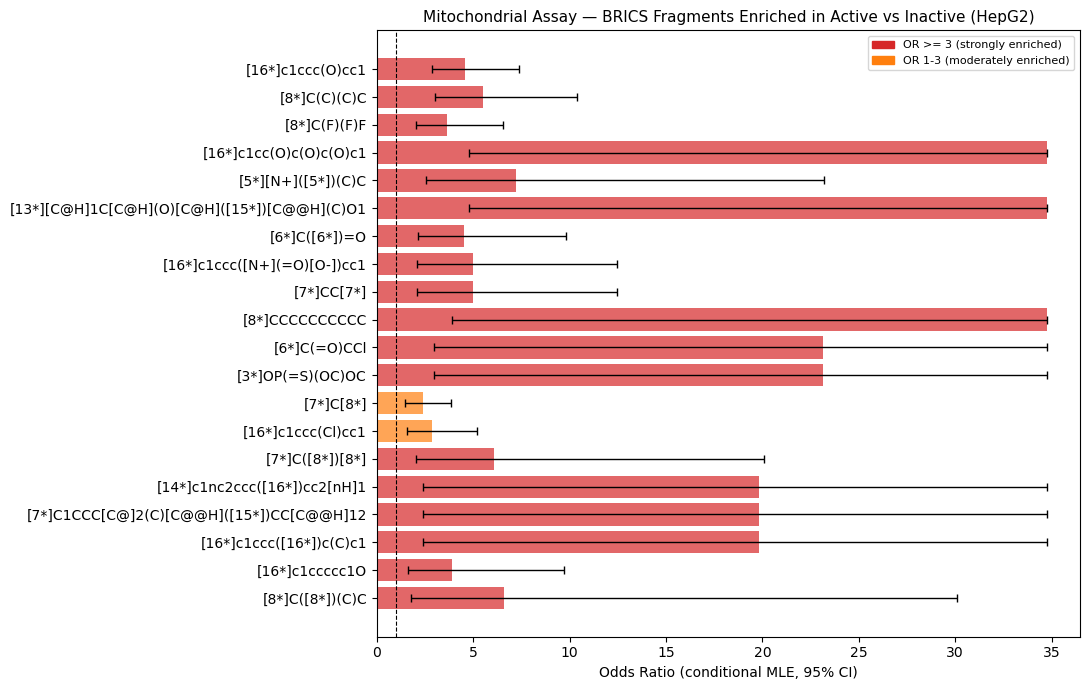


Mitochondrial Assay — Top Enriched BRICS Fragments (Active Compounds, HepG2) — top 12 enriched BRICS fragments:


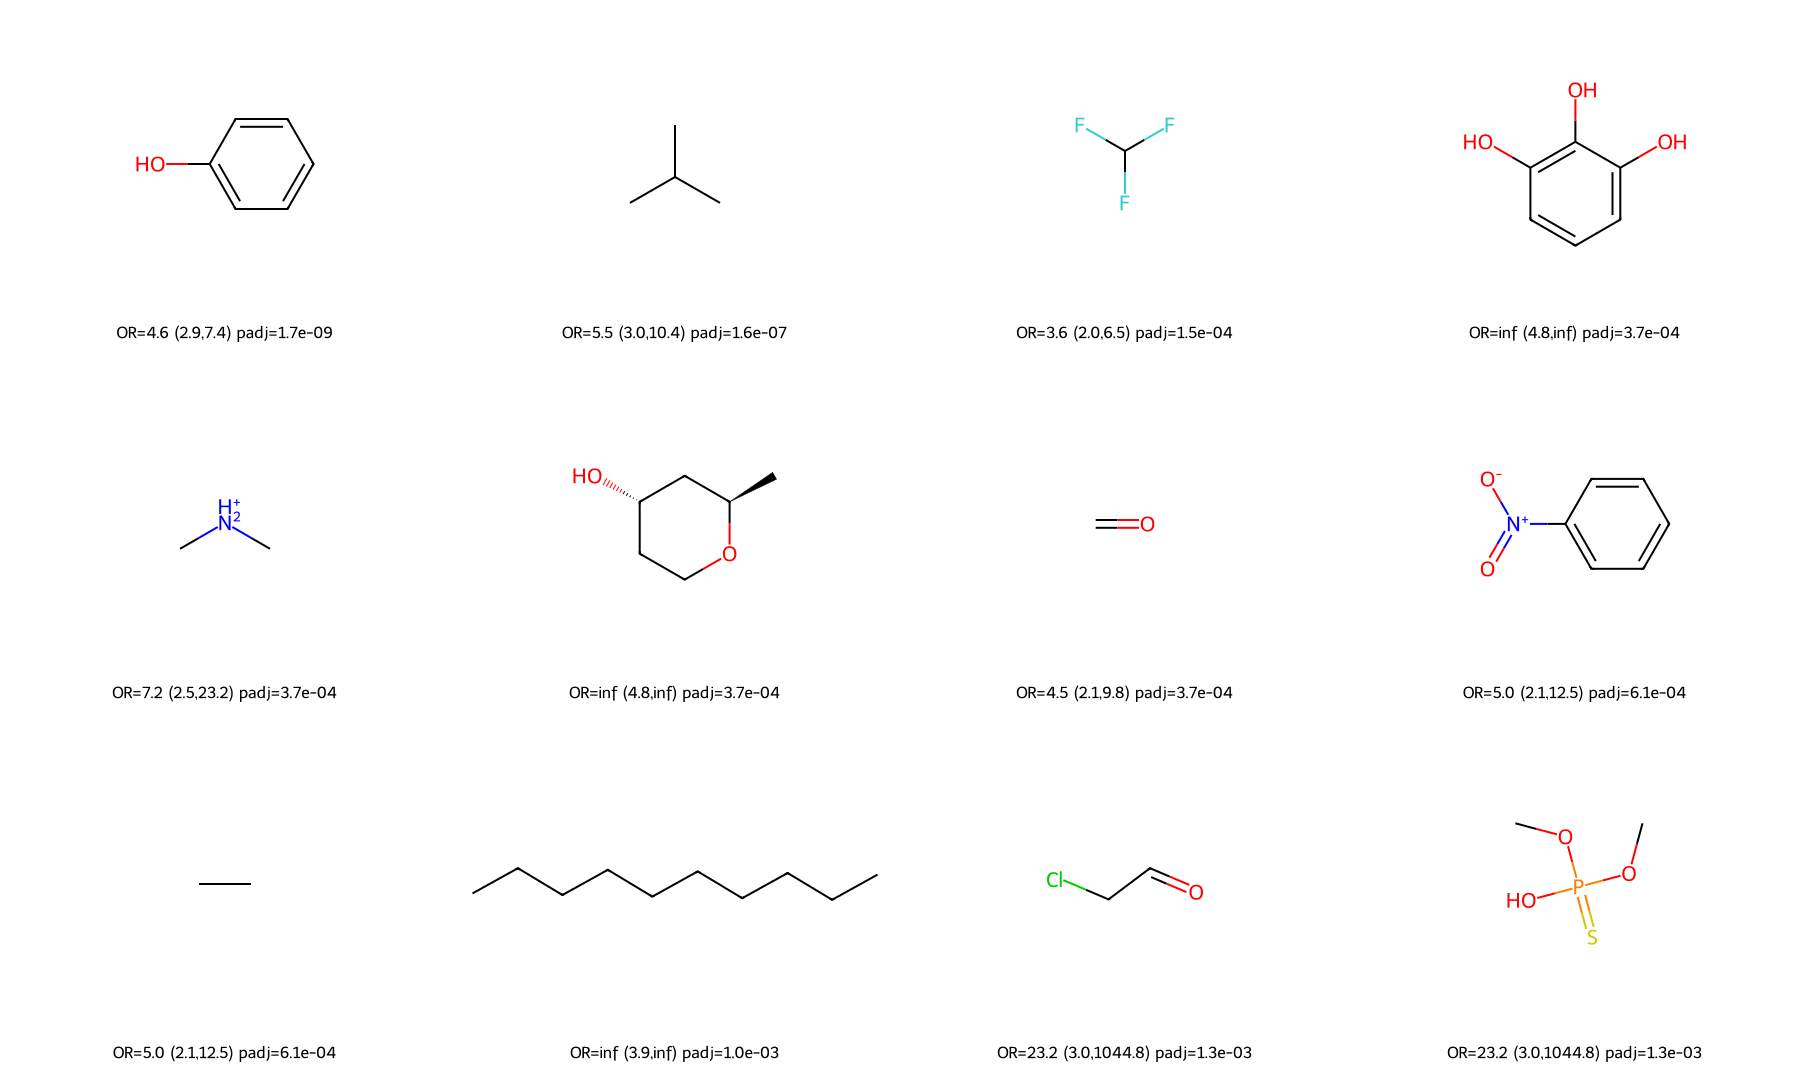

In [222]:
# ── Bar chart ────────────────────────────────────────────────────────────────
bar_enrichment(
    enrich_mito,
    title='Mitochondrial Assay — BRICS Fragments Enriched in Active vs Inactive (HepG2)'
)

# ── Structure grid ───────────────────────────────────────────────────────────
draw_frags(
    enrich_mito,
    title='Mitochondrial Assay — Top Enriched BRICS Fragments (Active Compounds, HepG2)'
)

Fragments enriched in Mito-INACTIVE (depleted in active): 7
      fragment  n_mito_inactive  pct_mito_inactive  n_mito_active  pct_mito_active  odds_ratio     padj
[1*]C(=O)C[4*]               50           1.564456              2         0.205761    7.706156 0.005051
    [6*]C(=O)O              136           4.255319             17         1.748971    2.496306 0.005051
    [4*]CC[8*]               54           1.689612              3         0.308642    5.549875 0.006313
[1*]C(=O)C[8*]               25           0.782228              0         0.000000         inf 0.019722
      [4*]CC=C               25           0.782228              0         0.000000         inf 0.019722
       [4*]CCO               66           2.065081              7         0.720165    2.906346 0.026364
        [8*]CN               21           0.657071              0         0.000000         inf 0.041018


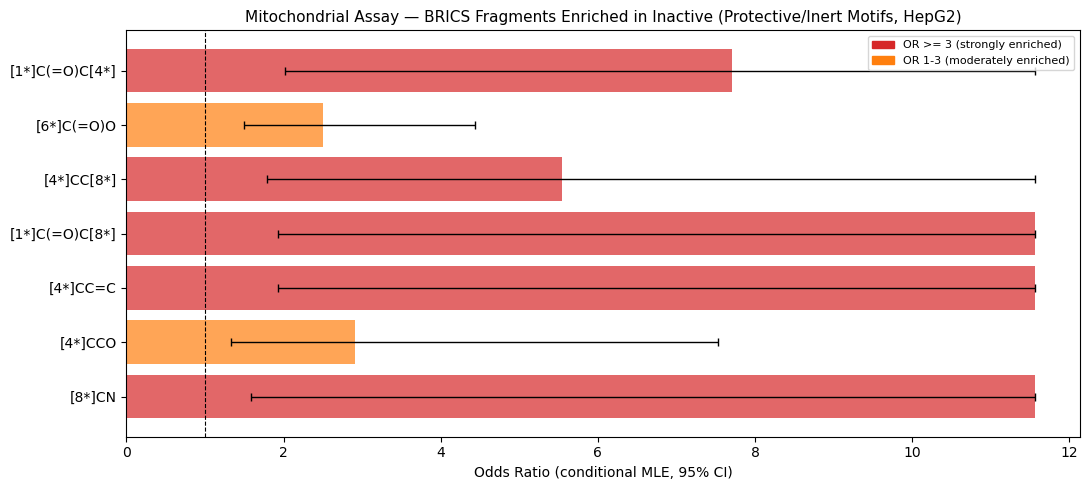


Mitochondrial Assay — Top BRICS Fragments Enriched in Inactive Compounds (HepG2) — top 7 enriched BRICS fragments:


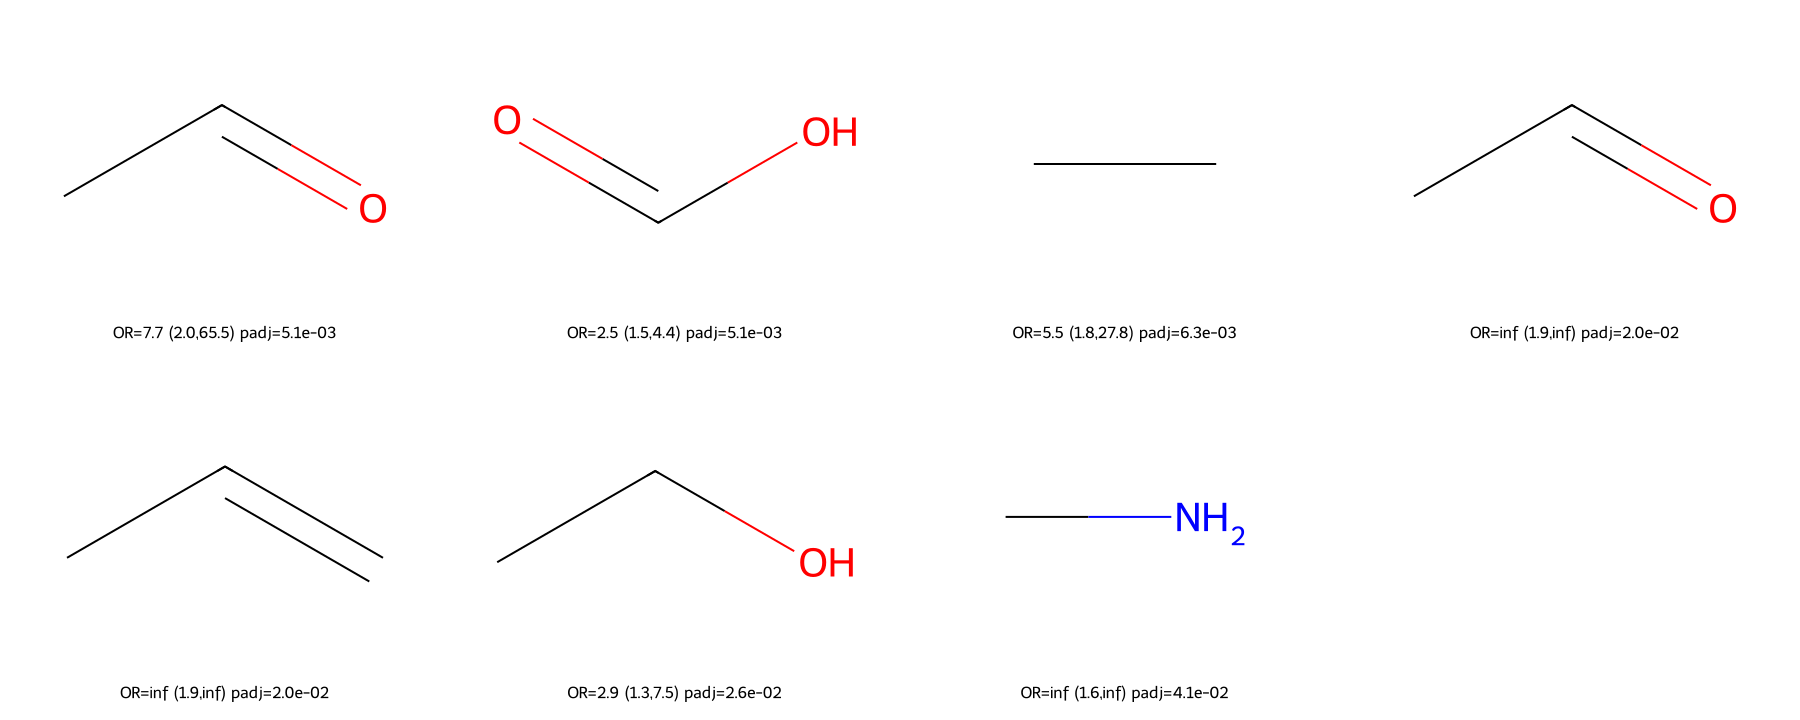

In [223]:
# ── Reverse direction: fragments enriched in MITO-INACTIVE ──────────────────
enrich_mito_inv = fisher_enrichment(
    mito_inactive_sets, mito_active_sets,
    label_a='mito_inactive', label_b='mito_active',
    min_count=15, fdr_alpha=0.05
)

print(f'Fragments enriched in Mito-INACTIVE (depleted in active): {len(enrich_mito_inv)}')
if not enrich_mito_inv.empty:
    print(enrich_mito_inv[['fragment', 'n_mito_inactive', 'pct_mito_inactive',
                            'n_mito_active', 'pct_mito_active', 'odds_ratio', 'padj']].head(15).to_string(index=False))

bar_enrichment(
    enrich_mito_inv,
    title='Mitochondrial Assay — BRICS Fragments Enriched in Inactive (Protective/Inert Motifs, HepG2)'
)
draw_frags(
    enrich_mito_inv,
    title='Mitochondrial Assay — Top BRICS Fragments Enriched in Inactive Compounds (HepG2)'
)

In [224]:
# ── Generate fragment PNG images for Analysis B (Mito Active vs Inactive) ────
# Thresholds: min_count=6, fdr_alpha=0.01, OR>=2  →  24 fragments
import os
from rdkit.Chem.Draw import rdMolDraw2D

FIGS = BASE + "figures/"
os.makedirs(FIGS, exist_ok=True)

def save_frag_png(filename, brics_smi, size=(300, 250)):
    mol = Chem.MolFromSmiles(clean_frag(brics_smi))
    if not mol:
        print(f"  FAILED: {filename}"); return
    drawer = rdMolDraw2D.MolDraw2DCairo(*size)
    drawer.drawOptions().addStereoAnnotation = False
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    with open(FIGS + filename, "wb") as fh:
        fh.write(drawer.GetDrawingText())
    print(f"  OK: {filename}")

# Phenolic
save_frag_png("mi_frag_phenol.png",               "[16*]c1ccc(O)cc1")
save_frag_png("mi_frag_pyrogallol.png",           "[16*]c1cc(O)c(O)c(O)c1")
save_frag_png("mi_frag_ortho_hydroxyphenyl.png",  "[16*]c1ccccc1O")
# Lipophilic / alkyl
save_frag_png("mi_frag_tbutyl.png",               "[8*]C(C)(C)C")
save_frag_png("mi_frag_decyl.png",                "[8*]CCCCCCCCCC")
save_frag_png("mi_frag_octyl.png",                "[4*]CCCCCCCC")
save_frag_png("mi_frag_dodecyl.png",              "[8*]CCCCCCCCCCCC")
save_frag_png("mi_frag_isobutyl_disub.png",       "[8*]C([8*])(C)C")
save_frag_png("mi_frag_methylene.png",            "[8*]C[8*]")
save_frag_png("mi_frag_methylene_bridge.png",     "[7*]C[8*]")
save_frag_png("mi_frag_methine.png",              "[7*]C([8*])[8*]")
save_frag_png("mi_frag_ethylene.png",             "[7*]CC[7*]")
save_frag_png("mi_frag_decalin.png",              "[7*]C1CCC[C@]2(C)[C@@H]([15*])CC[C@@H]12")
# Halogenated
save_frag_png("mi_frag_cf3.png",                  "[8*]C(F)(F)F")
save_frag_png("mi_frag_chloroacetyl.png",         "[6*]C(=O)CCl")
save_frag_png("mi_frag_chlorobenzene.png",        "[16*]c1ccc(Cl)cc1")
# Nitroaromatic
save_frag_png("mi_frag_nitrophenyl_para.png",     "[16*]c1ccc([N+](=O)[O-])cc1")
# Carbonyl
save_frag_png("mi_frag_carbonyl_disub.png",       "[6*]C([6*])=O")
# Nitrogen-containing
save_frag_png("mi_frag_dimethylamine.png",        "[5*][N+]([5*])(C)C")
save_frag_png("mi_frag_benzimidazole.png",        "[14*]c1nc2ccc([16*])cc2[nH]1")
save_frag_png("mi_frag_tolyl_disub.png",          "[16*]c1ccc([16*])c(C)c1")
save_frag_png("mi_frag_pyridyl.png",              "[14*]c1ncccc1[16*]")
# Organophosphate
save_frag_png("mi_frag_dimethylthiophosphate.png","[3*]OP(=S)(OC)OC")
# Complex ring / sugar
save_frag_png("mi_frag_methyloxanol.png",         "[13*][C@H]1C[C@H](O)[C@H]([15*])[C@@H](C)O1")
print("All 24 Analysis B fragment PNGs saved.")


  OK: mi_frag_phenol.png
  OK: mi_frag_pyrogallol.png
  OK: mi_frag_ortho_hydroxyphenyl.png
  OK: mi_frag_tbutyl.png
  OK: mi_frag_decyl.png
  OK: mi_frag_octyl.png
  OK: mi_frag_dodecyl.png
  OK: mi_frag_isobutyl_disub.png
  OK: mi_frag_methylene.png
  OK: mi_frag_methylene_bridge.png
  OK: mi_frag_methine.png
  OK: mi_frag_ethylene.png
  OK: mi_frag_decalin.png
  OK: mi_frag_cf3.png
  OK: mi_frag_chloroacetyl.png
  OK: mi_frag_chlorobenzene.png
  OK: mi_frag_nitrophenyl_para.png
  OK: mi_frag_carbonyl_disub.png
  OK: mi_frag_dimethylamine.png
  OK: mi_frag_benzimidazole.png
  OK: mi_frag_tolyl_disub.png
  OK: mi_frag_pyridyl.png
  OK: mi_frag_dimethylthiophosphate.png
  OK: mi_frag_methyloxanol.png
All 24 Analysis B fragment PNGs saved.


---
## Summary

| Analysis | Foreground | Background | Enriched Fragments |
|----------|-----------|------------|--------------------|
| Table 7 — Both Active | Mito+Viability active | Mito+Viability inactive | See `enrich_t7` |
| Mito Active vs Inactive | Mito active | Mito inactive | See `enrich_mito` |

Fragments appearing in **both** analyses are especially noteworthy — they drive mitochondrial dysfunction
and are robust to whether viability is measured concurrently.


In [225]:
# ── Overlap: fragments significant in BOTH analyses ──────────────────────────
if not enrich_t7.empty and not enrich_mito.empty:
    shared = set(enrich_t7['fragment']) & set(enrich_mito['fragment'])
    t7_only   = set(enrich_t7['fragment']) - set(enrich_mito['fragment'])
    mito_only = set(enrich_mito['fragment']) - set(enrich_t7['fragment'])

    print(f'Fragments enriched in BOTH Table 7 and Mito analyses: {len(shared)}')
    print(f'Fragments unique to Table 7 (Mito+Viability both-active): {len(t7_only)}')
    print(f'Fragments unique to Mito analysis: {len(mito_only)}')

    if shared:
        print('\n-- Shared fragments (consistent across both analyses) --')
        for f in sorted(shared):
            print(' ', f)
else:
    print('One or both analyses returned no significant fragments — cannot compute overlap.')

Fragments enriched in BOTH Table 7 and Mito analyses: 10
Fragments unique to Table 7 (Mito+Viability both-active): 7
Fragments unique to Mito analysis: 14

-- Shared fragments (consistent across both analyses) --
  [16*]c1cc(O)c(O)c(O)c1
  [16*]c1ccc(Cl)cc1
  [16*]c1ccc(O)cc1
  [16*]c1ccc([16*])c(C)c1
  [3*]OP(=S)(OC)OC
  [4*]CCCCCCCC
  [5*][N+]([5*])(C)C
  [7*]C([8*])[8*]
  [8*]C(C)(C)C
  [8*]C(F)(F)F


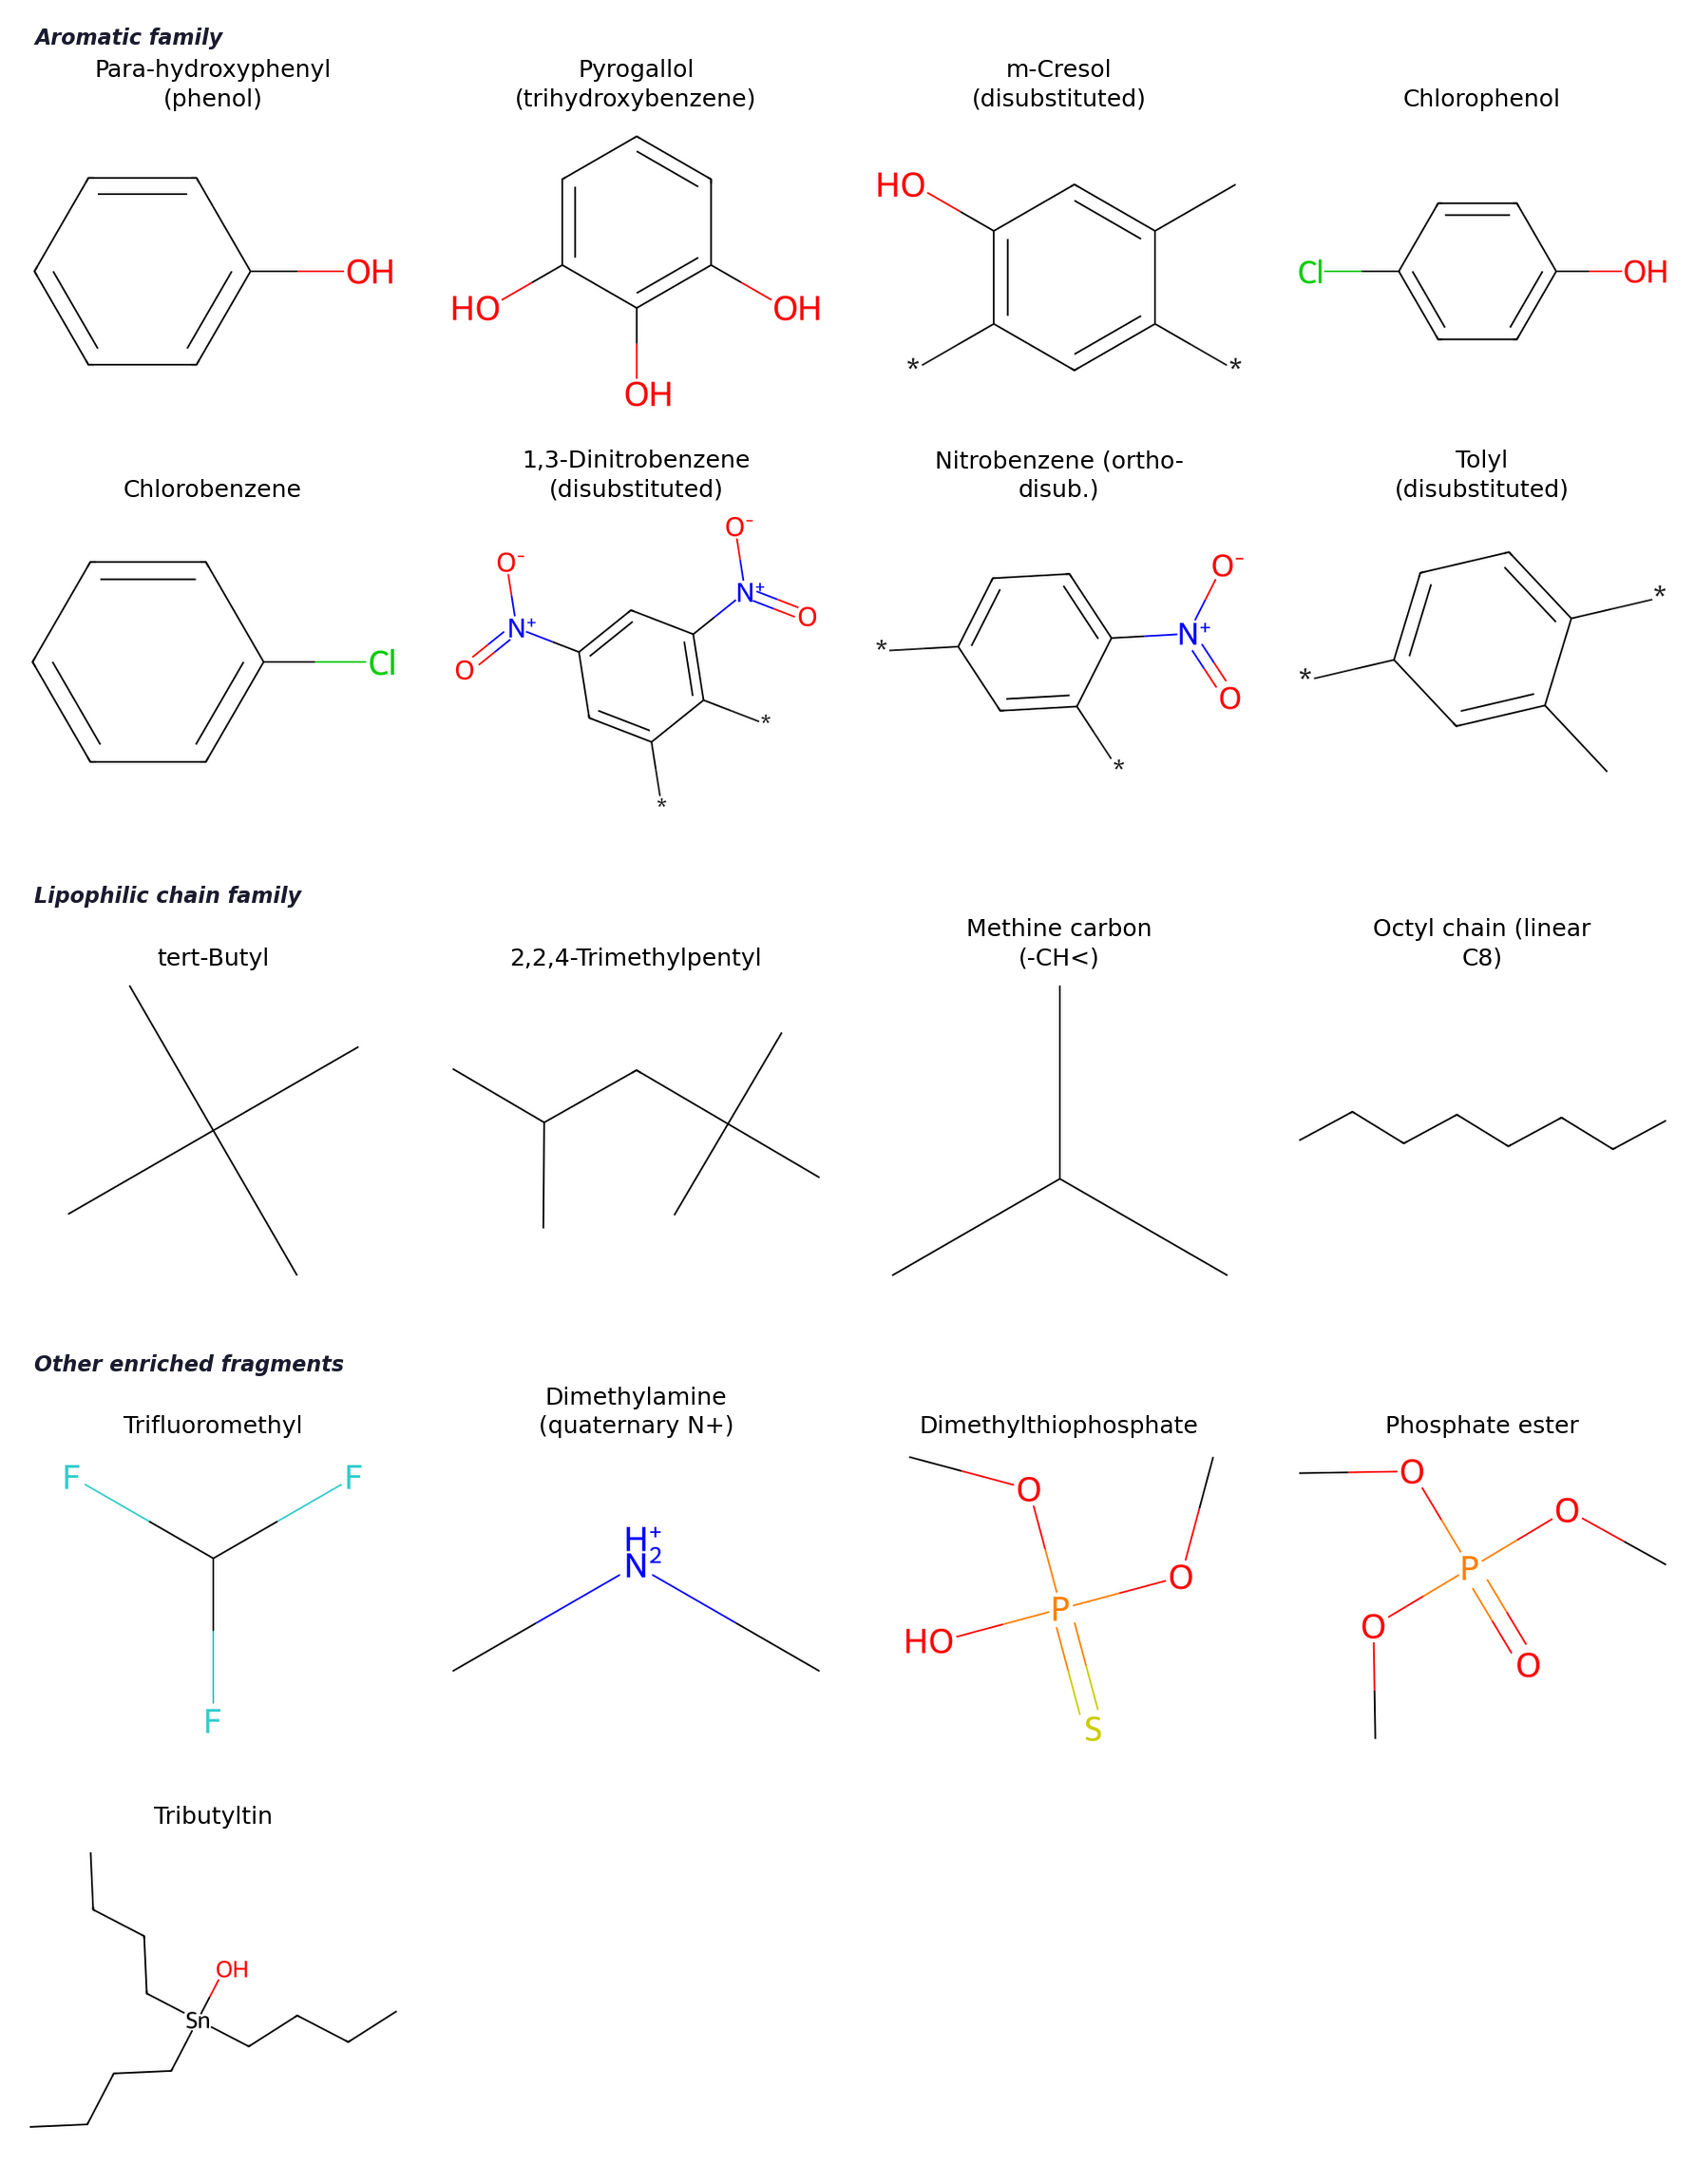

Saved -> /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_mito_viab_t7_fragments.png


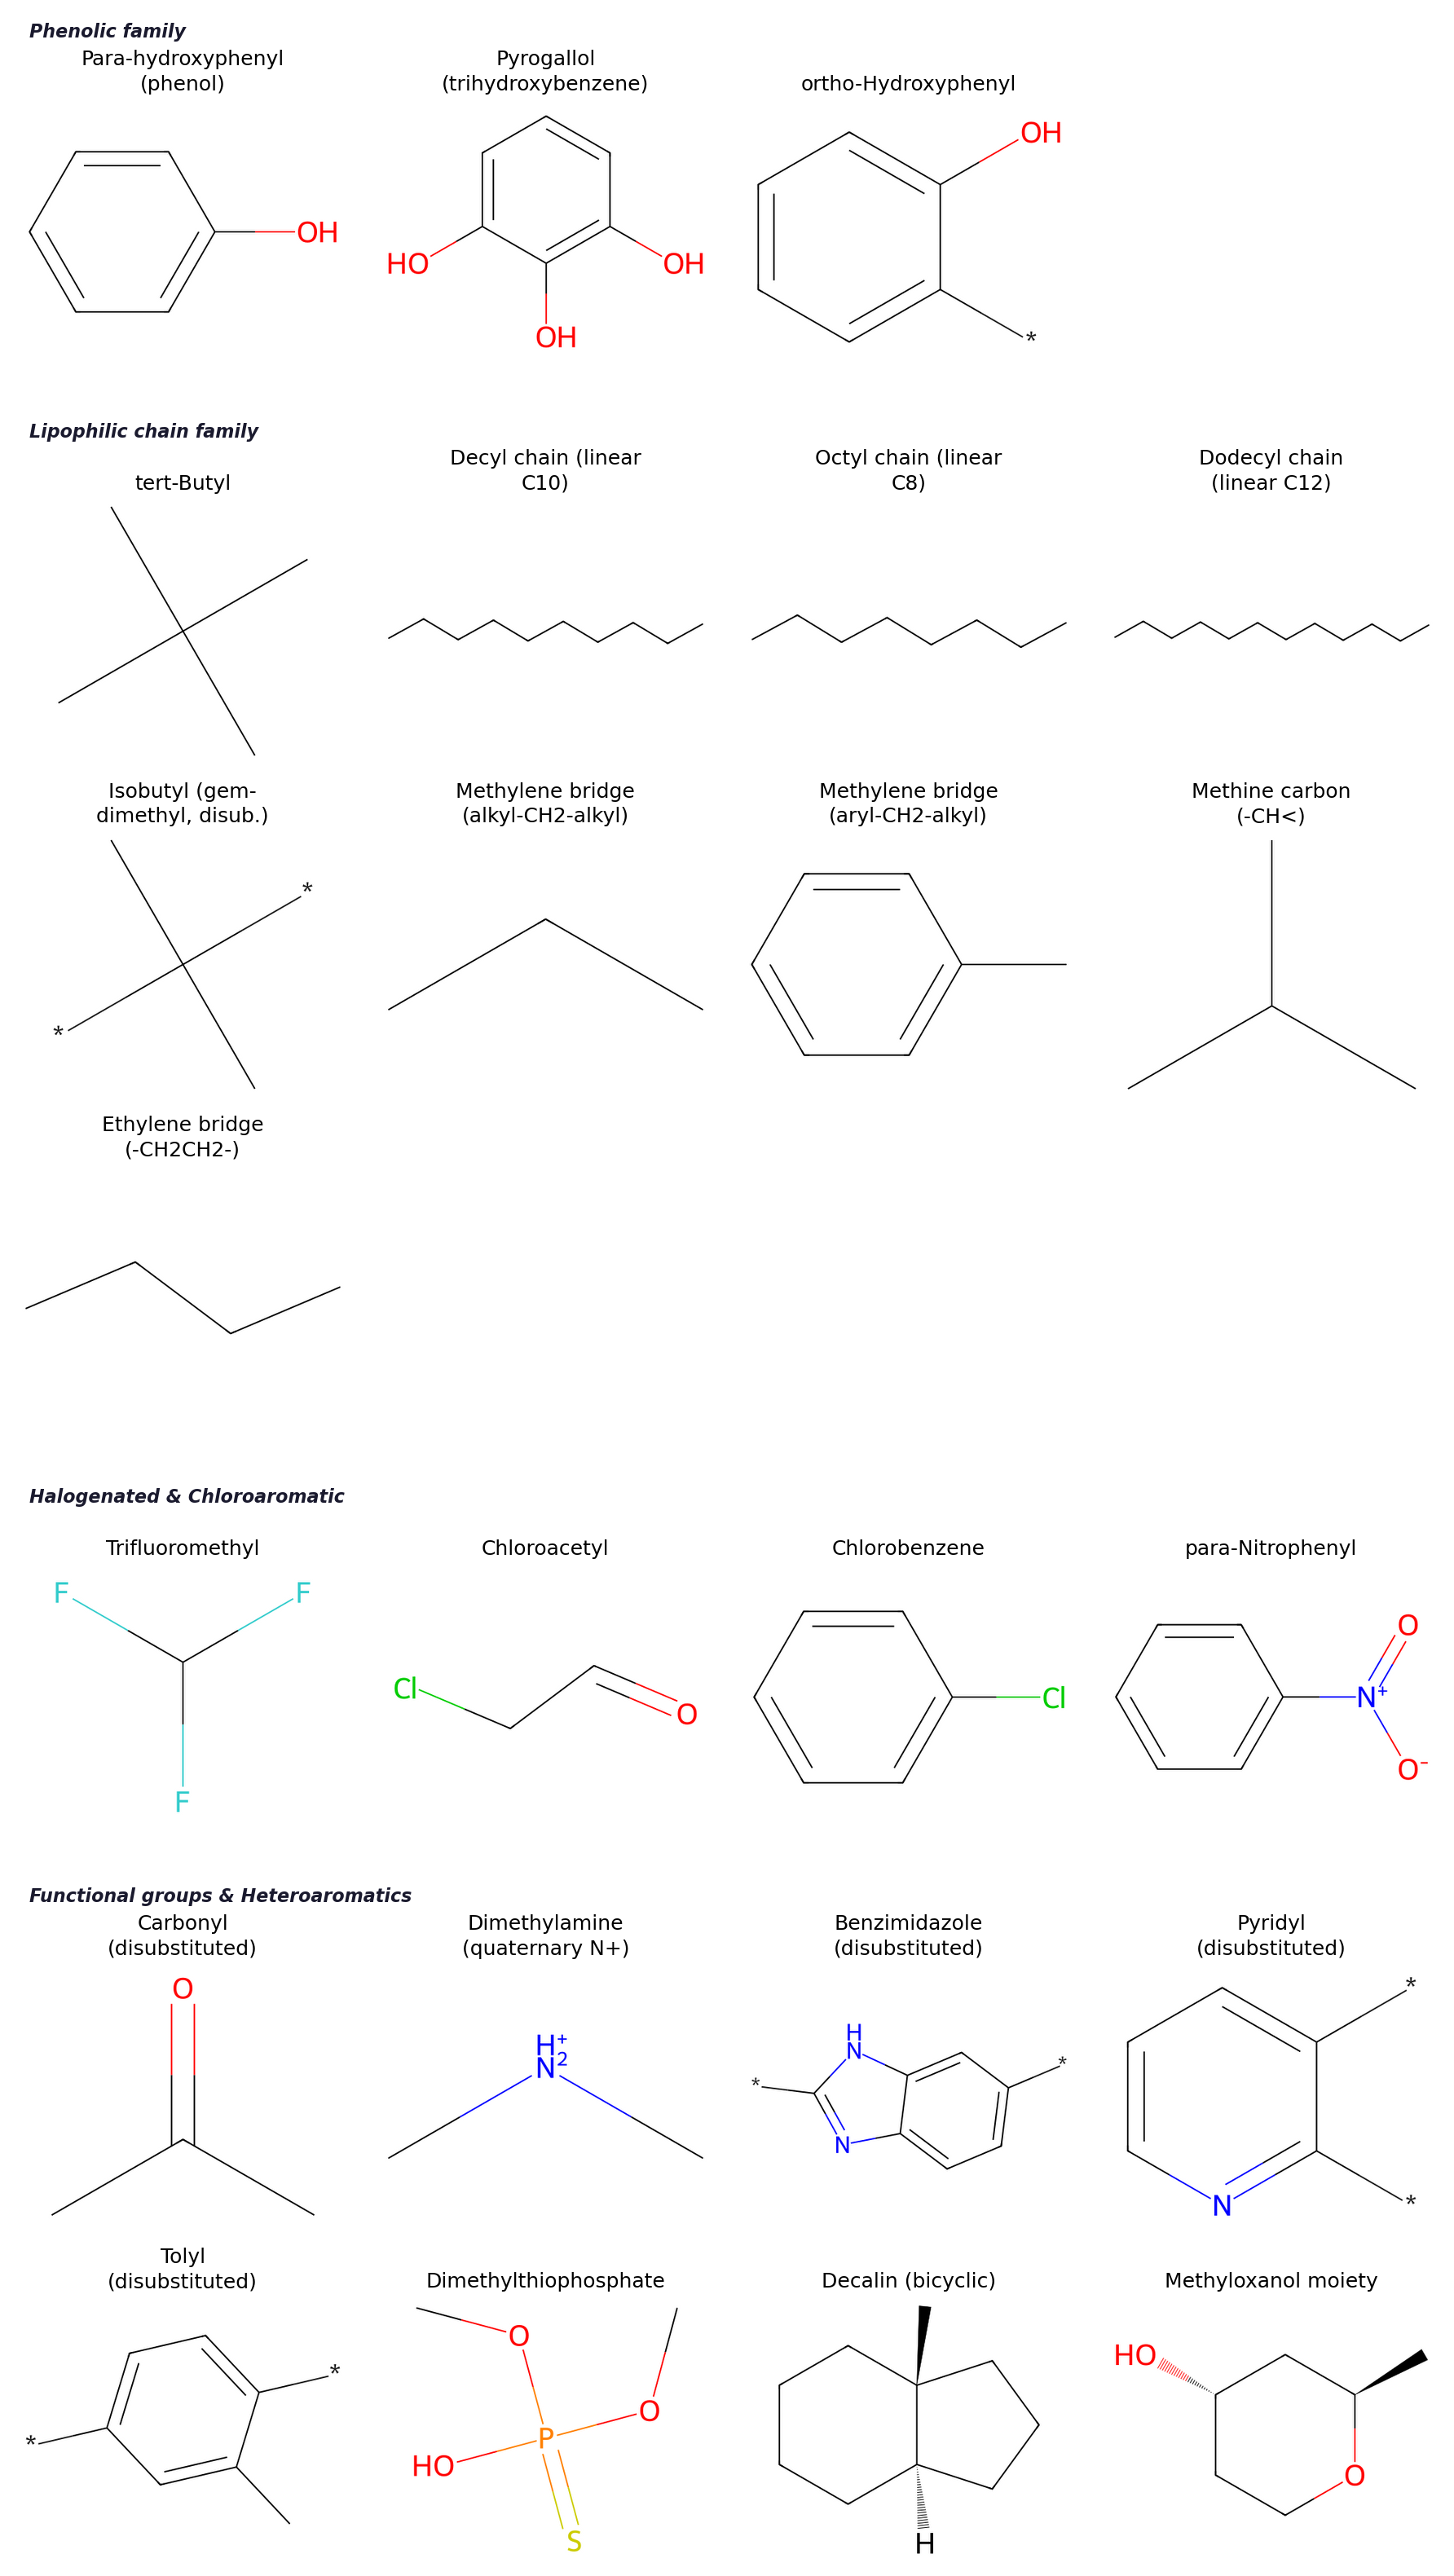

Saved -> /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_mito_active_fragments.png


In [226]:
# ── Main-text figures: Analysis A (Table 7) & Analysis B (Mito Active) ──────
# Generates two panel figures for paper body, grouped by structural family.
# SMILES verified against BRICS fragment output; representatives used where
# cleaning collapses to trivial structures (methane/ethane etc.).

import os, textwrap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from rdkit import Chem
from rdkit.Chem import Draw

FIGS = BASE + 'figures/'
os.makedirs(FIGS, exist_ok=True)

IMG_W, IMG_H = 480, 380

def smiles_to_rgb(smi, w=IMG_W, h=IMG_H):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.ones((h, w, 3), dtype=np.uint8) * 255
    return np.asarray(Draw.MolToImage(mol, size=(w, h)).convert('RGB'))

def make_fragment_figure(families, ncols, out_path, hdr_colours, hdr_edges):
    row_plan = []
    for fam_name, frags in families:
        row_plan.append(('header', fam_name))
        for i in range(0, len(frags), ncols):
            chunk = frags[i : i + ncols]
            row_plan.append(('mols', [(lbl, smiles_to_rgb(smi)) for lbl, smi in chunk]))
    H_HDR, H_MOL = 0.65, 4.2
    fig_w = ncols * 4.5
    hrs = [H_HDR if r[0] == 'header' else H_MOL for r in row_plan]
    fig = plt.figure(figsize=(fig_w, sum(hrs) + 0.3), facecolor='white')
    gs  = gridspec.GridSpec(len(row_plan), ncols, figure=fig,
                            height_ratios=hrs, hspace=0.08, wspace=0.04,
                            left=0.01, right=0.99, top=0.99, bottom=0.01)
    hdr_idx = 0
    for ri, rp in enumerate(row_plan):
        if rp[0] == 'header':
            ax = fig.add_subplot(gs[ri, :])
            ax.set_facecolor(hdr_colours[hdr_idx % len(hdr_colours)])
            for sp in ax.spines.values():
                sp.set_edgecolor(hdr_edges[hdr_idx % len(hdr_edges)])
                sp.set_linewidth(0.8)
            ax.text(0.015, 0.5, rp[1], transform=ax.transAxes,
                    fontsize=16, fontweight='bold', fontstyle='italic',
                    va='center', ha='left', color='#1A1A2E')
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)
            ax.set_xticks([]); ax.set_yticks([])
            hdr_idx += 1
        else:
            for ci in range(ncols):
                ax = fig.add_subplot(gs[ri, ci])
                ax.axis('off')
                if ci < len(rp[1]):
                    lbl, arr = rp[1][ci]
                    ax.imshow(arr, aspect='equal', interpolation='lanczos')
                    wrapped = '\n'.join(textwrap.wrap(lbl, width=20, break_long_words=False))
                    ax.set_title(wrapped, fontsize=18, pad=3,
                                 multialignment='center', linespacing=1.35)
    fig.savefig(out_path, dpi=250, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved -> {out_path}')

# ── Analysis A: Mito+Viability Both-Active vs Both-Inactive (17 fragments) ───
# Representative SMILES notes:
#   tbutyl         : CC(C)(C)C  neopentane — shows C(CH3)3, distinct from methine
#   methine        : CC(C)C     isobutane  — shows -CH<, would clean to methane
#   phosphate      : COP(=O)(OC)OC — trimethyl phosphate, shows ester bonds
#   dimethylamine  : C[NH2+]C  — faithful to cleaned BRICS [5*][N+]([5*])(C)C
#   mcresol_disub, dinitrobenzene, nitro_orth, tolyl_disub: [*] kept for position clarity

FAMILIES_A = [
    ('Aromatic family', [
        ('Para-hydroxyphenyl (phenol)',        'Oc1ccccc1'),
        ('Pyrogallol (trihydroxybenzene)',      'Oc1cccc(O)c1O'),
        ('m-Cresol (disubstituted)',            '[*]c1cc([*])c(O)cc1C'),
        ('Chlorophenol',                        'Oc1ccc(Cl)cc1'),
        ('Chlorobenzene',                       'Clc1ccccc1'),
        ('1,3-Dinitrobenzene (disubstituted)', '[*]c1cc([N+](=O)[O-])cc([N+](=O)[O-])c1[*]'),
        ('Nitrobenzene (ortho-disub.)',         '[*]c1ccc([N+](=O)[O-])c([*])c1'),
        ('Tolyl (disubstituted)',               '[*]c1ccc([*])c(C)c1'),
    ]),
    ('Lipophilic chain family', [
        ('tert-Butyl',                          'CC(C)(C)C'),
        ('2,2,4-Trimethylpentyl',               'CC(C)CC(C)(C)C'),
        ('Methine carbon (-CH<)',               'CC(C)C'),
        ('Octyl chain (linear C8)',             'CCCCCCCC'),
    ]),
    ('Other enriched fragments', [
        ('Trifluoromethyl',                     'FC(F)F'),
        ('Dimethylamine (quaternary N+)',       'C[NH2+]C'),
        ('Dimethylthiophosphate',               'COP(=S)(OC)O'),
        ('Phosphate ester',                     'COP(=O)(OC)OC'),
        ('Tributyltin',                         'CCCC[Sn](O)(CCCC)CCCC'),
    ]),
]

HDR_A = ['#FFF', '#FFF', '#FFF']
EDG_A = ['#FFF', '#FFF', '#FFF']
make_fragment_figure(FAMILIES_A, ncols=4,
                     out_path=FIGS + 'fig_mito_viab_t7_fragments.png',
                     hdr_colours=HDR_A, hdr_edges=EDG_A)

# ── Analysis B: Mito Active vs Inactive (24 fragments) ───────────────────────
# Representative SMILES notes:
#   ortho_oh        : [*]c1ccccc1O  — [*] kept to show OH ortho to attachment
#   isobutyl_disub  : [*]C([*])(C)C — [*] kept to show gem-dimethyl + 2 connections
#   methylene alkyl : CCC    — propane, shows alkyl-CH2-alkyl
#   methylene aryl  : Cc1ccccc1 — toluene, shows aryl-CH2-alkyl context
#   methine         : CC(C)C — isobutane, -CH< representative
#   ethylene        : CCCC   — butane, shows -CH2CH2- bridge
#   carbonyl_disub  : CC(=O)C — acetone, shows C=O with two substituents
#   benzimidazole, pyridyl, tolyl_disub: [*] kept for disubstituted positions
#   decalin         : cleaned stereo SMILES from BRICS decomposition
#   methyloxanol    : cleaned stereo SMILES from BRICS decomposition

FAMILIES_B = [
    ('Phenolic family', [
        ('Para-hydroxyphenyl (phenol)', 'Oc1ccccc1'),
        ('Pyrogallol (trihydroxybenzene)', 'Oc1cccc(O)c1O'),
        ('ortho-Hydroxyphenyl',          '[*]c1ccccc1O'),
    ]),
    ('Lipophilic chain family', [
        ('tert-Butyl',                   'CC(C)(C)C'),
        ('Decyl chain (linear C10)',     'CCCCCCCCCC'),
        ('Octyl chain (linear C8)',      'CCCCCCCC'),
        ('Dodecyl chain (linear C12)',   'CCCCCCCCCCCC'),
        ('Isobutyl (gem-dimethyl, disub.)', '[*]C([*])(C)C'),
        ('Methylene bridge (alkyl-CH2-alkyl)', 'CCC'),
        ('Methylene bridge (aryl-CH2-alkyl)', 'Cc1ccccc1'),
        ('Methine carbon (-CH<)',        'CC(C)C'),
        ('Ethylene bridge (-CH2CH2-)',   'CCCC'),
    ]),
    ('Halogenated & Chloroaromatic', [
        ('Trifluoromethyl',              'FC(F)F'),
        ('Chloroacetyl',                 'O=CCCl'),
        ('Chlorobenzene',                'Clc1ccccc1'),
        ('para-Nitrophenyl',             'O=[N+]([O-])c1ccccc1'),
    ]),
    ('Functional groups & Heteroaromatics', [
        ('Carbonyl (disubstituted)',     'CC(=O)C'),
        ('Dimethylamine (quaternary N+)', 'C[NH2+]C'),
        ('Benzimidazole (disubstituted)', '[*]c1nc2ccc([*])cc2[nH]1'),
        ('Pyridyl (disubstituted)',      '[*]c1ncccc1[*]'),
        ('Tolyl (disubstituted)',        '[*]c1ccc([*])c(C)c1'),
        ('Dimethylthiophosphate',        'COP(=S)(OC)O'),
        ('Decalin (bicyclic)',           '[H]C1CCC[C@]2(C)[C@@H]([H])CC[C@@H]12'),
        ('Methyloxanol moiety',         '[H][C@H]1C[C@H](O)[C@H]([H])[C@@H](C)O1'),
    ]),
]

HDR_B = ['#FFF', '#FFF', '#FFF', '#FFF']
EDG_B = ['#FFF', '#FFF', '#FFF', '#FFF']
make_fragment_figure(FAMILIES_B, ncols=4,
                     out_path=FIGS + 'fig_mito_active_fragments.png',
                     hdr_colours=HDR_B, hdr_edges=EDG_B)

---
## Analysis C — Mitochondria Assay (AID_720635): Active vs Inactive

Direct comparison using **all 1,412 mito-active** vs **3,213 mito-inactive** compounds
from the cleaned mitochondria assay file (AID_720635), irrespective of cell viability outcome.

| Group | Definition | N |
|---|---|---|
| **Mito Active** | Active in AID_720635 | 1,412 |
| **Mito Inactive** | Inactive in AID_720635 | 3,213 |


In [227]:
# ── Analysis C: Load directly from AID_720635_cleaned.csv ─────────────────────
CLEANED = BASE + "cleaned_datasets/"
mito_raw = pd.read_csv(CLEANED + "AID_720635_cleaned.csv",
                       usecols=["PUBCHEM_CID", "PUBCHEM_EXT_DATASOURCE_SMILES",
                                "PUBCHEM_ACTIVITY_OUTCOME"])
mito_raw = mito_raw.dropna(subset=["PUBCHEM_CID", "PUBCHEM_EXT_DATASOURCE_SMILES",
                                    "PUBCHEM_ACTIVITY_OUTCOME"])
mito_raw["PUBCHEM_CID"] = mito_raw["PUBCHEM_CID"].astype(int)
mito_raw = mito_raw.drop_duplicates("PUBCHEM_CID").reset_index(drop=True)

c_active   = mito_raw[mito_raw["PUBCHEM_ACTIVITY_OUTCOME"] == "Active"].reset_index(drop=True)
c_inactive = mito_raw[mito_raw["PUBCHEM_ACTIVITY_OUTCOME"] == "Inactive"].reset_index(drop=True)

print(f"Mito Active  : {len(c_active):5d} unique CIDs")
print(f"Mito Inactive: {len(c_inactive):5d} unique CIDs")


Mito Active  :  1412 unique CIDs
Mito Inactive:  3213 unique CIDs


In [228]:
# ── BRICS fragments ────────────────────────────────────────────────────────────
c_active_sets   = [brics_frags(s) for s in c_active["PUBCHEM_EXT_DATASOURCE_SMILES"]]
c_inactive_sets = [brics_frags(s) for s in c_inactive["PUBCHEM_EXT_DATASOURCE_SMILES"]]

print(f"Fragments computed for {sum(len(s)>0 for s in c_active_sets)}/{len(c_active_sets)} active")
print(f"Fragments computed for {sum(len(s)>0 for s in c_inactive_sets)}/{len(c_inactive_sets)} inactive")

# ── Fisher enrichment: active vs inactive ──────────────────────────────────────
enrich_c = fisher_enrichment(
    c_active_sets, c_inactive_sets,
    label_a="mito_active", label_b="mito_inactive",
    fdr_alpha=0.01
)

print(f"Significantly enriched fragments in Mito-Active vs Mito-Inactive: {len(enrich_c)}")
if len(enrich_c):
    cols = ["fragment", "n_mito_active", "pct_mito_active",
            "n_mito_inactive", "pct_mito_inactive", "odds_ratio", "padj"]
    print(enrich_c[cols].to_string(index=False))


[17:42:24] WARNING: not removing hydrogen atom without neighbors
[17:42:24] WARNING: not removing hydrogen atom without neighbors
[17:42:25] WARNING: not removing hydrogen atom without neighbors


Fragments computed for 1412/1412 active
Fragments computed for 3213/3213 inactive
Significantly enriched fragments in Mito-Active vs Mito-Inactive: 36
                                        fragment  n_mito_active  pct_mito_active  n_mito_inactive  pct_mito_inactive  odds_ratio         padj
                                [16*]c1ccc(O)cc1             72         5.099150               35           1.089325    4.876906 5.393910e-13
                                    [8*]C(C)(C)C             46         3.257790               19           0.591348    5.658558 2.196785e-09
                                    [8*]C(F)(F)F             48         3.399433               27           0.840336    4.151040 1.225565e-07
                               [16*]c1ccc(Cl)cc1             42         2.974504               27           0.840336    3.616375 7.972363e-06
                                   [6*]C([6*])=O             30         2.124646               14           0.435730    4.958268 1.123803e-

In [233]:
# ── PubChem name lookup for Analysis C enriched fragments ─────────────────────
import json as _json
import urllib.request
import urllib.parse
import time

def pubchem_name(smiles_clean, timeout=10):
    """Query PubChem PUG REST for preferred name of a BRICS fragment SMILES."""
    mol = Chem.MolFromSmiles(smiles_clean)
    canon = Chem.MolToSmiles(mol) if mol else smiles_clean
    enc  = urllib.parse.quote(canon, safe='')
    base = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/{enc}"
    try:
        with urllib.request.urlopen(
                f"{base}/property/IUPACName,Title/JSON", timeout=timeout) as r:
            p = _json.loads(r.read())['PropertyTable']['Properties'][0]
        cid   = p.get('CID')
        title = p.get('Title') or p.get('IUPACName')
        iupac = p.get('IUPACName')
        if title:
            return cid, title, iupac
        with urllib.request.urlopen(
                f"{base}/synonyms/JSON", timeout=timeout) as r:
            syns = _json.loads(r.read())['InformationList']['Information'][0].get('Synonym', [])
        return cid, syns[0] if syns else None, iupac
    except Exception as e:
        return None, None, f'error: {e}'

# ── Run on all 36 enriched fragments from Analysis C ─────────────────────────
rows = []
for _, row in enrich_c.iterrows():
    cleaned = clean_frag(row['fragment'])
    cid, title, iupac = pubchem_name(cleaned)
    n_active_col   = [c for c in enrich_c.columns if c.startswith('n_') and 'inactive' not in c][0]
    n_inactive_col = [c for c in enrich_c.columns if c.startswith('n_') and 'inactive' in c][0]
    rows.append({
        'brics_fragment':  row['fragment'],
        'cleaned_smiles':  cleaned,
        'pubchem_cid':     cid,
        'preferred_name':  title,
        'iupac_name':      iupac,
        'n_active':        row[n_active_col],
        'n_inactive':      row[n_inactive_col],
        'odds_ratio':      row['odds_ratio'],
        'padj':            row['padj'],
    })
    time.sleep(0.25)  # be polite to PubChem API

names_c = pd.DataFrame(rows)
print(f"Names looked up for {len(names_c)} fragments\n")
pd.set_option('display.max_colwidth', 40)
print(names_c[['preferred_name', 'iupac_name', 'odds_ratio', 'padj',
               'n_active', 'n_inactive', 'cleaned_smiles']].to_string(index=False))


Names looked up for 36 fragments

                                     preferred_name                                          iupac_name  odds_ratio         padj  n_active  n_inactive                               cleaned_smiles
                                             Phenol                                              phenol    4.876906 5.393910e-13        72          35                               [H]c1ccc(O)cc1
                                          Isobutane                                     2-methylpropane    5.658558 2.196785e-09        46          19                                  [H]C(C)(C)C
                                   Trifluoromethane                                          fluoroform    4.151040 1.225565e-07        48          27                                  [H]C(F)(F)F
                                      Chlorobenzene                                       chlorobenzene    3.616375 7.972363e-06        42          27                              [H

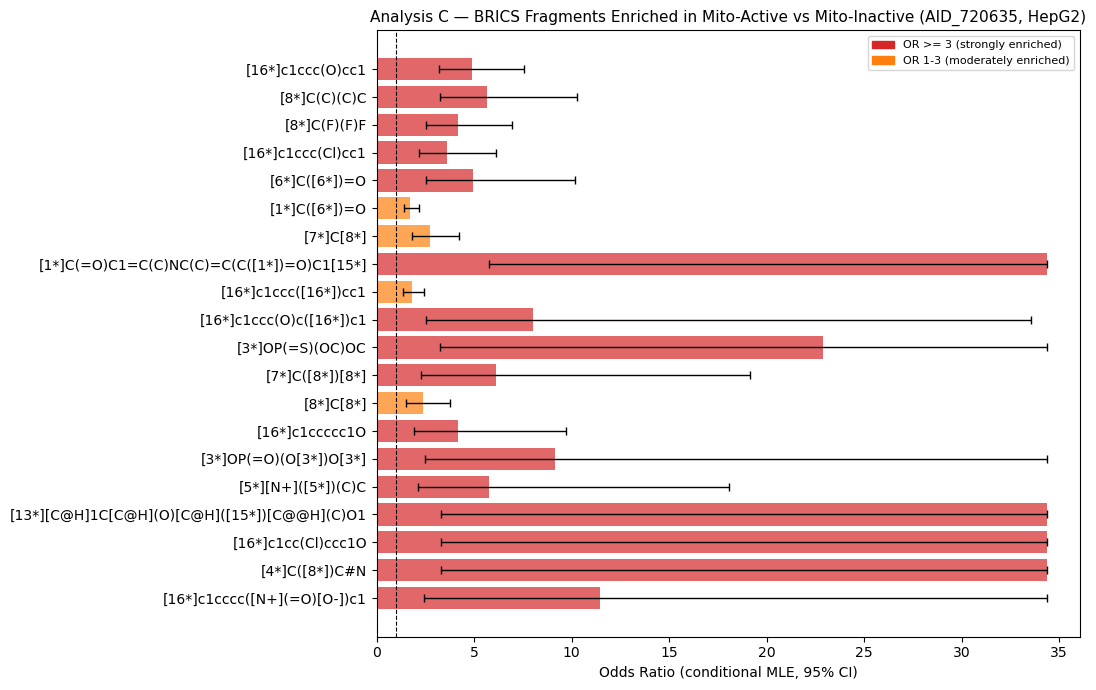


Analysis C — Top Enriched BRICS Fragments (Mito-Active, AID_720635) — top 12 enriched BRICS fragments:


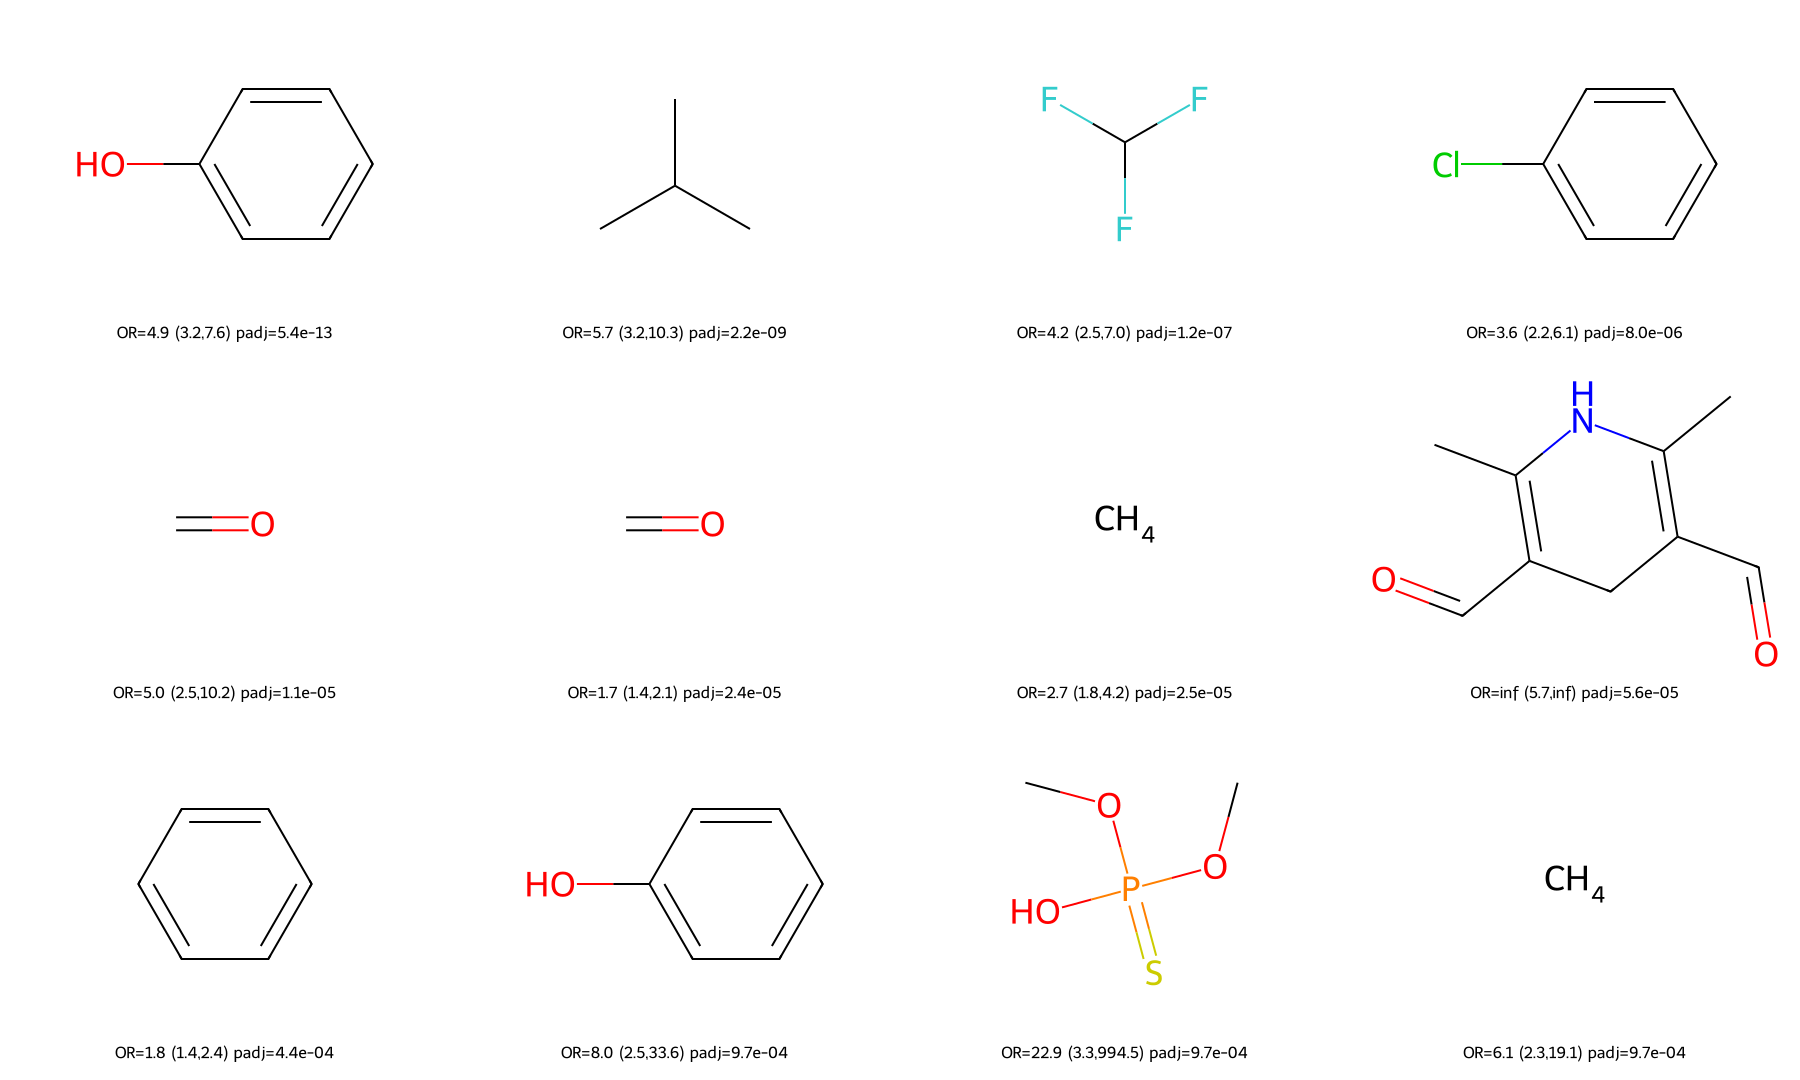

In [234]:
# ── Bar chart & fragment grid ───────────────────────────────────────────────────
if len(enrich_c):
    bar_enrichment(enrich_c, title="Analysis C — BRICS Fragments Enriched in Mito-Active vs Mito-Inactive (AID_720635, HepG2)")
    draw_frags(enrich_c,
               title="Analysis C — Top Enriched BRICS Fragments (Mito-Active, AID_720635)",
               top_n=12, mols_per_row=4)


Fragments enriched in Mito-INACTIVE (depleted in mito-active): 4
      fragment  n_mito_inactive  pct_mito_inactive  n_mito_active  pct_mito_active  odds_ratio     padj
    [6*]C(=O)O              137           4.263928             23         1.628895    2.689269 0.000465
[1*]C(=O)C[8*]               26           0.809213              0         0.000000         inf 0.007190
      [4*]CC=C               26           0.809213              0         0.000000         inf 0.007190
[1*]C(=O)C[4*]               50           1.556178              4         0.283286    5.563007 0.007190


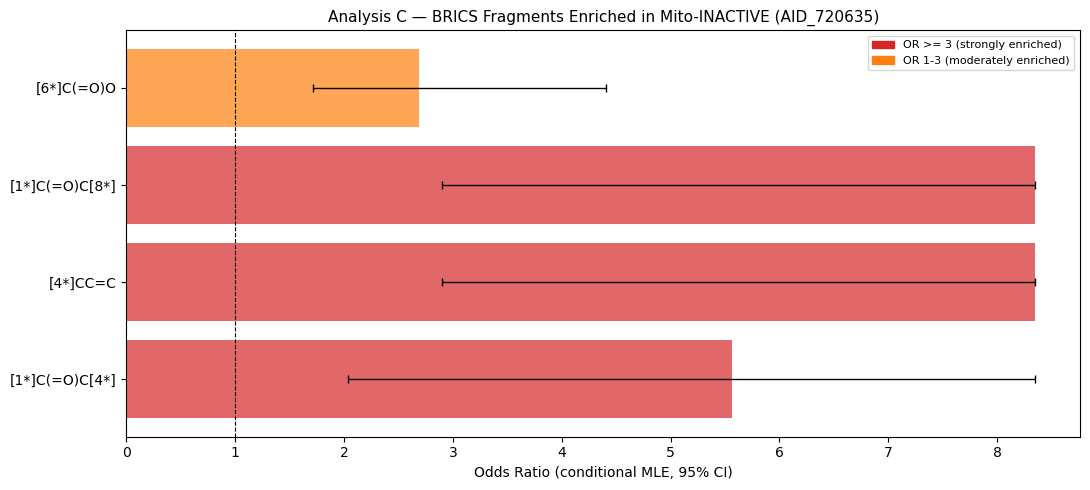

In [235]:
# ── Reverse: fragments enriched in Mito-INACTIVE ───────────────────────────────
enrich_c_inv = fisher_enrichment(
    c_inactive_sets, c_active_sets,
    label_a="mito_inactive", label_b="mito_active",
    fdr_alpha=0.01
)

print(f"Fragments enriched in Mito-INACTIVE (depleted in mito-active): {len(enrich_c_inv)}")
if len(enrich_c_inv):
    print(enrich_c_inv[["fragment", "n_mito_inactive", "pct_mito_inactive",
                         "n_mito_active", "pct_mito_active", "odds_ratio", "padj"]].head(15).to_string(index=False))
    bar_enrichment(enrich_c_inv,
                   title="Analysis C — BRICS Fragments Enriched in Mito-INACTIVE (AID_720635)")


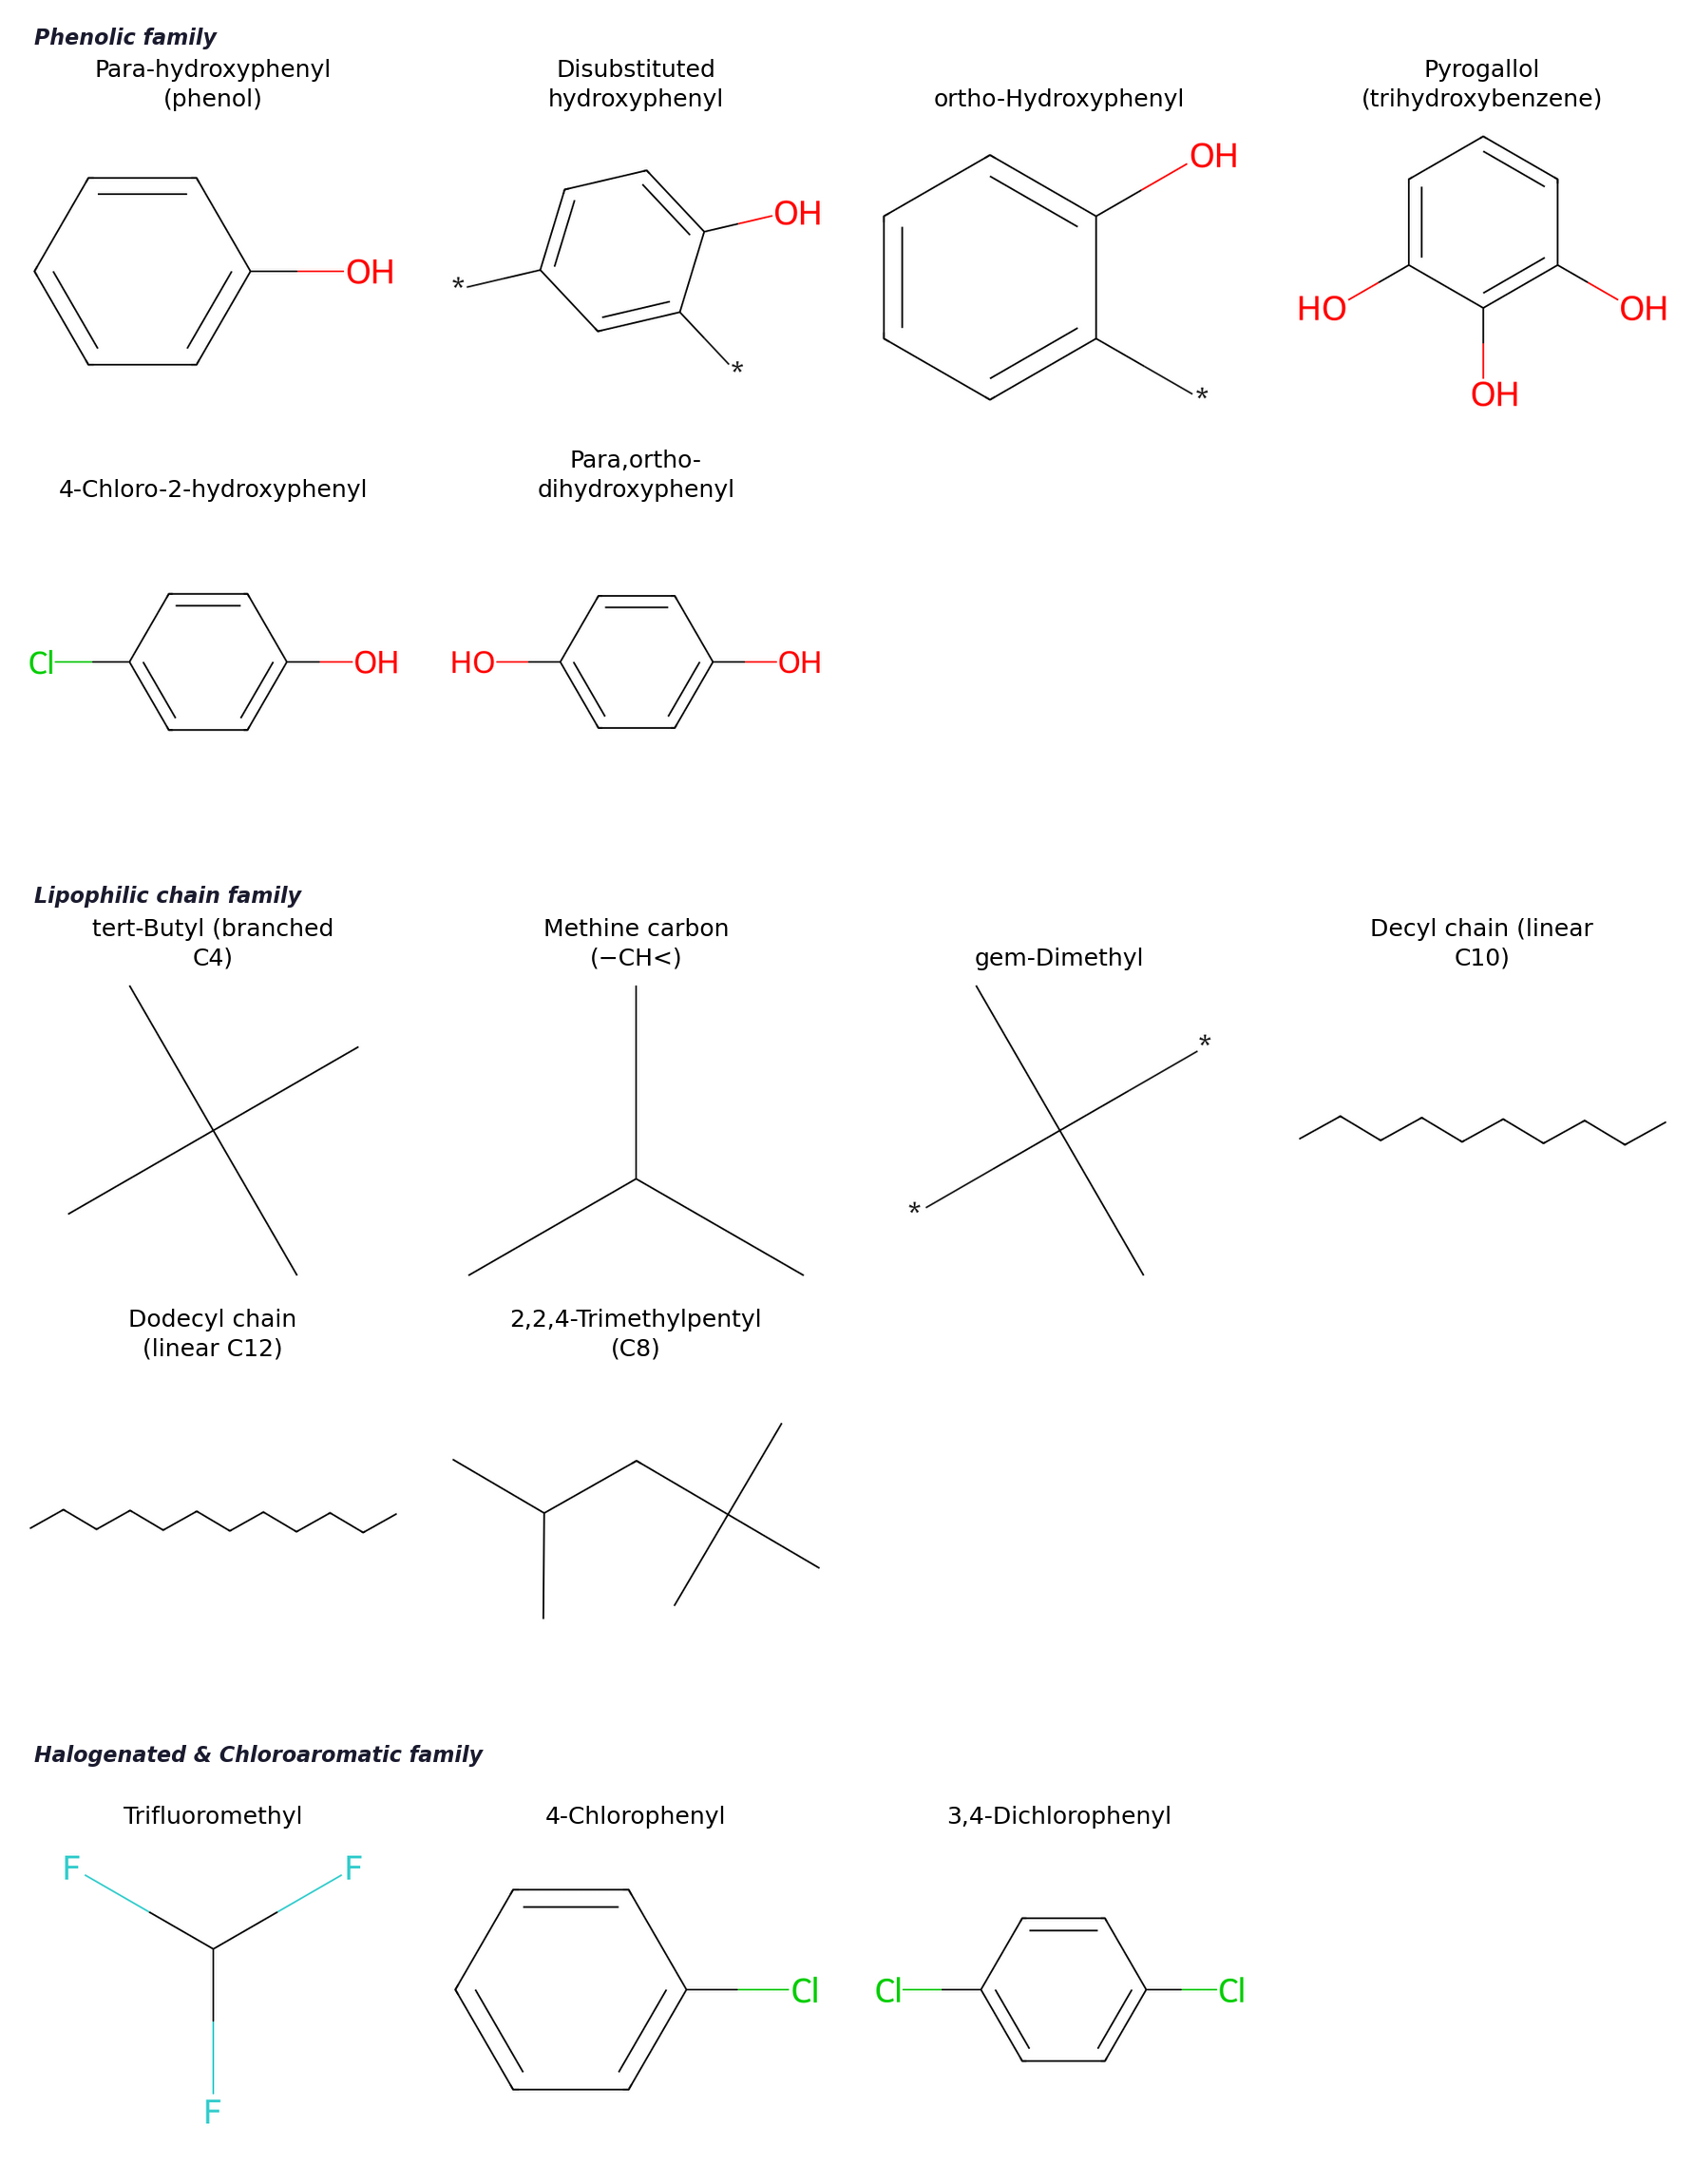

Saved -> /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_mito_c_fragments_part1.png


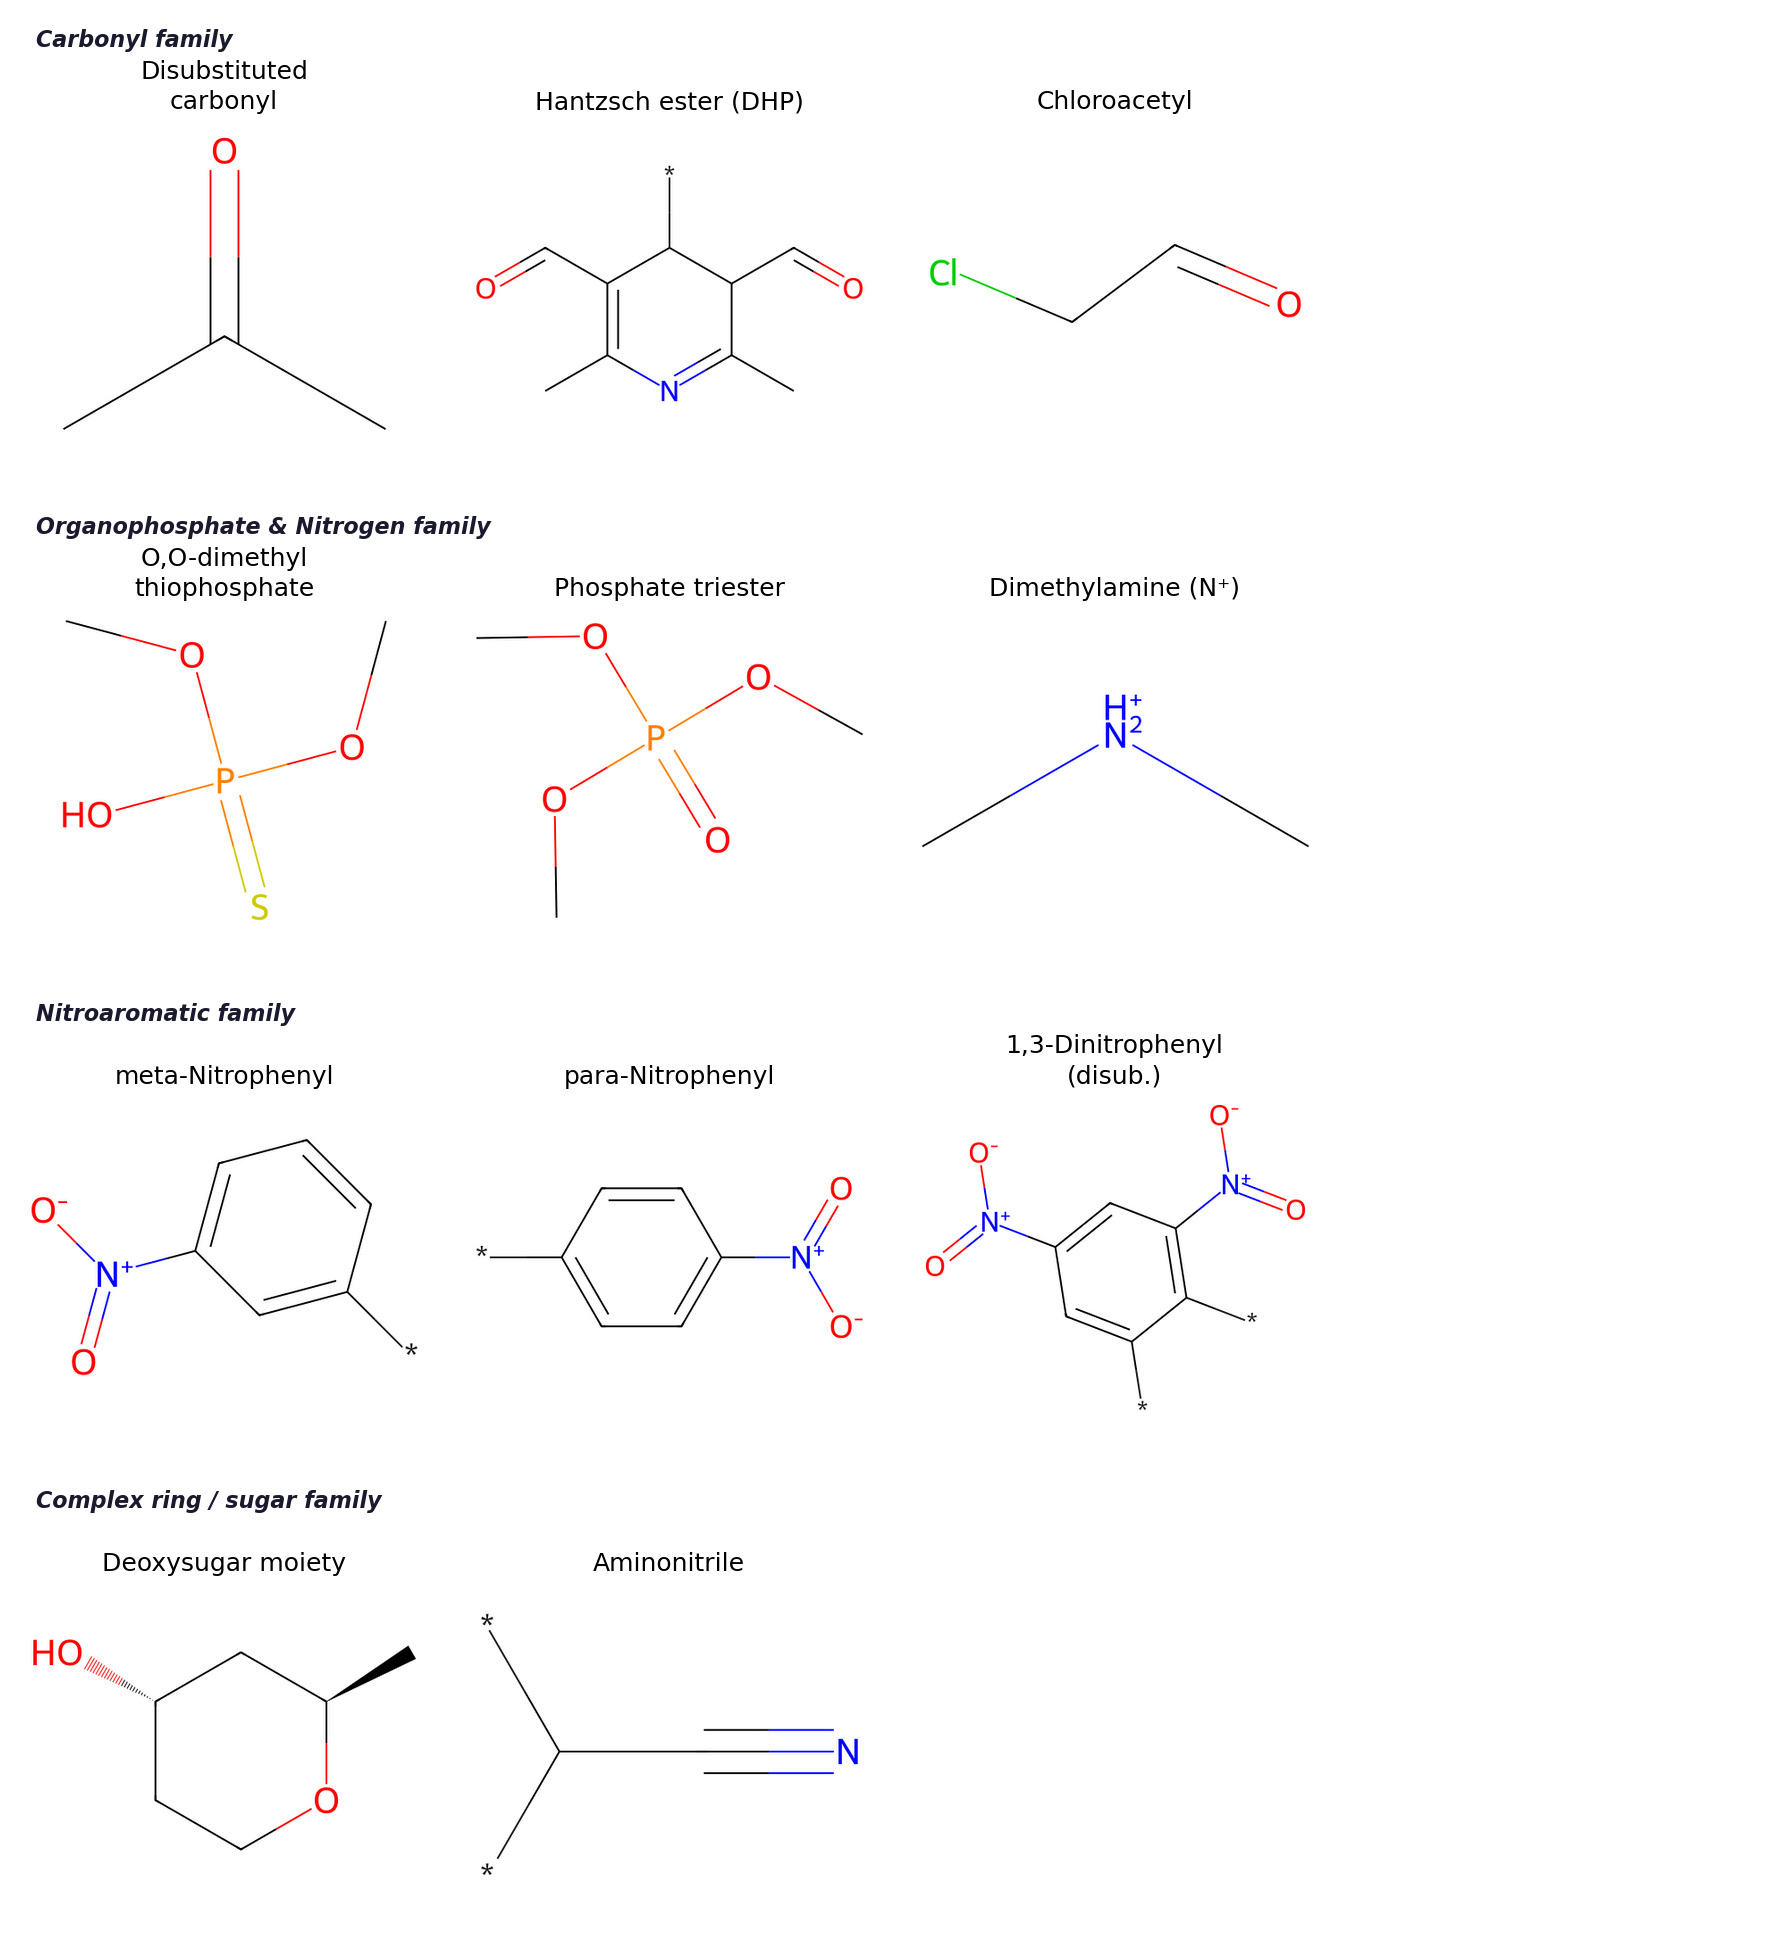

Saved -> /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_mito_c_fragments_part2.png
  OK: mc_frag_00.png
  OK: mc_frag_01.png
  OK: mc_frag_02.png
  OK: mc_frag_03.png
  OK: mc_frag_04.png
  OK: mc_frag_05.png
  OK: mc_frag_06.png
  OK: mc_frag_07.png
  OK: mc_frag_08.png
  OK: mc_frag_09.png
  OK: mc_frag_10.png
  OK: mc_frag_11.png
  OK: mc_frag_12.png
  OK: mc_frag_13.png
  OK: mc_frag_14.png
  OK: mc_frag_15.png
  OK: mc_frag_16.png
  OK: mc_frag_17.png
  OK: mc_frag_18.png
  OK: mc_frag_19.png
  OK: mc_frag_20.png
  OK: mc_frag_21.png
  OK: mc_frag_22.png
  OK: mc_frag_23.png
  OK: mc_frag_24.png
  OK: mc_frag_25.png
  OK: mc_frag_26.png
  OK: mc_frag_27.png
  OK: mc_frag_28.png
  OK: mc_frag_29.png
  OK: mc_frag_30.png
  OK: mc_frag_31.png
  OK: mc_frag_32.png
  OK: mc_frag_33.png
  OK: mc_frag_34.png
  OK: mc_frag_35.png
All Analysis C fragment PNGs saved.


In [232]:
# ── Analysis C: two-part panel figure ─────────────────────────────────────────
import os, textwrap, re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D

FIGS = BASE + "figures/"
os.makedirs(FIGS, exist_ok=True)

# ── Part 1: Phenolic + Lipophilic + Halogenated & Chloroaromatic ──────────────
FAMILIES_C1 = [
    ("Phenolic family", [
        ("Para-hydroxyphenyl (phenol)",      "Oc1ccccc1"),
        ("Disubstituted hydroxyphenyl",      "[*]c1ccc(O)c([*])c1"),
        ("ortho-Hydroxyphenyl",              "[*]c1ccccc1O"),
        ("Pyrogallol (trihydroxybenzene)",   "Oc1cccc(O)c1O"),
        ("4-Chloro-2-hydroxyphenyl",         "Oc1ccc(Cl)cc1"),
        ("Para,ortho-dihydroxyphenyl",       "Oc1ccc(O)cc1"),
    ]),
    ("Lipophilic chain family", [
        ("tert-Butyl (branched C4)",         "CC(C)(C)C"),
        ("Methine carbon (\u2212CH<)",       "CC(C)C"),
        ("gem-Dimethyl",                     "[*]C([*])(C)C"),
        ("Decyl chain (linear C10)",         "CCCCCCCCCC"),
        ("Dodecyl chain (linear C12)",       "CCCCCCCCCCCC"),
        ("2,2,4-Trimethylpentyl (C8)",       "CC(C)CC(C)(C)C"),
    ]),
    ("Halogenated & Chloroaromatic family", [
        ("Trifluoromethyl",                  "FC(F)F"),
        ("4-Chlorophenyl",                   "Clc1ccccc1"),
        ("3,4-Dichlorophenyl",               "Clc1ccc(Cl)cc1"),
    ]),
]

# ── Part 2: Carbonyl + Organophosphate & Nitrogen + Nitroaromatic + Complex ───
FAMILIES_C2 = [
    ("Carbonyl family", [
        ("Disubstituted carbonyl",           "CC(=O)C"),
        ("Hantzsch ester (DHP)",             "CC1=NC(C)=C(C=O)C([*])C1C=O"),
        ("Chloroacetyl",                     "O=CCCl"),
    ]),
    ("Organophosphate & Nitrogen family", [
        ("O,O-dimethyl thiophosphate",       "COP(=S)(OC)O"),
        ("Phosphate triester",               "COP(=O)(OC)OC"),
        ("Dimethylamine (N\u207a)",         "C[NH2+]C"),
    ]),
    ("Nitroaromatic family", [
        ("meta-Nitrophenyl",                 "O=[N+]([O-])c1cccc([*])c1"),
        ("para-Nitrophenyl",                 "O=[N+]([O-])c1ccc([*])cc1"),
        ("1,3-Dinitrophenyl (disub.)",       "[*]c1cc([N+](=O)[O-])cc([N+](=O)[O-])c1[*]"),
    ]),
    ("Complex ring / sugar family", [
        ("Deoxysugar moiety",                "[H][C@H]1C[C@H](O)[C@H]([H])[C@@H](C)O1"),
        ("Aminonitrile",                     "[*]C([*])C#N"),
    ]),
]

HDR1 = ["#FFF"] * len(FAMILIES_C1)
EDG1 = ["#FFF"] * len(FAMILIES_C1)
make_fragment_figure(FAMILIES_C1, ncols=4,
                     out_path=FIGS + "fig_mito_c_fragments_part1.png",
                     hdr_colours=HDR1, hdr_edges=EDG1)

HDR2 = ["#FFF"] * len(FAMILIES_C2)
EDG2 = ["#FFF"] * len(FAMILIES_C2)
make_fragment_figure(FAMILIES_C2, ncols=4,
                     out_path=FIGS + "fig_mito_c_fragments_part2.png",
                     hdr_colours=HDR2, hdr_edges=EDG2)

# ── Save individual PNGs for LaTeX table ──────────────────────────────────────
def save_frag_png_c(filename, brics_smi, size=(300, 250)):
    mol = Chem.MolFromSmiles(re.sub(r"\[\d+\*\]", "[*]", brics_smi))
    if not mol:
        print(f"  FAILED: {filename}"); return
    drawer = rdMolDraw2D.MolDraw2DCairo(*size)
    drawer.drawOptions().addStereoAnnotation = False
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    with open(FIGS + filename, "wb") as fh:
        fh.write(drawer.GetDrawingText())
    print(f"  OK: {filename}")

for i, row in enrich_c.iterrows():
    save_frag_png_c(f"mc_frag_{i:02d}.png", row["fragment"])
print("All Analysis C fragment PNGs saved.")
